In [4]:
import sys
print(sys.executable)
print(sys.version)

/home/suraj/Suraj_env/.venv/bin/python
3.10.12 (main, Jun 22 2026, 18:55:27) [GCC 11.4.0]


In [5]:
import sys
!{sys.executable} -m pip show shap

/home/suraj/Suraj_env/.venv/bin/python: No module named pip


In [1]:
import os
os.environ["PYOPENGL_PLATFORM"] = "osmesa"
os.environ["PYVISTA_OFF_SCREEN"] = "True"
os.environ["PYVISTA_USE_WGL"] = "True"
from os import environ
environ["CUDA_DEVICE_ORDER"]="PCI_BUS_ID"
environ['CUDA_VISIBLE_DEVICES'] = '0' #Select the GPU Card
print('Process id: ',os.getpid())

# Importing necessary libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.inspection import permutation_importance
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from tabulate import tabulate
from sklearn.utils.class_weight import compute_class_weight
import copy

from sklearn.metrics import roc_curve, auc
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import RocCurveDisplay
import shap

Process id:  5776


ModuleNotFoundError: No module named 'shap'

In [2]:
# Load the Excel file
# Macula_df = pd.read_excel("./Parameter_macula_up.xlsx", engine="openpyxl")  # Specify engine for .xlsx files
Macula_df = pd.read_excel("./Parameter_macula_up.xlsx")

# Display the first few rows
print(Macula_df.head(5))
print(Macula_df.columns.tolist())

ImportError: Missing optional dependency 'openpyxl'.  Use pip or conda to install openpyxl.

<Axes: xlabel='Label', ylabel='count'>

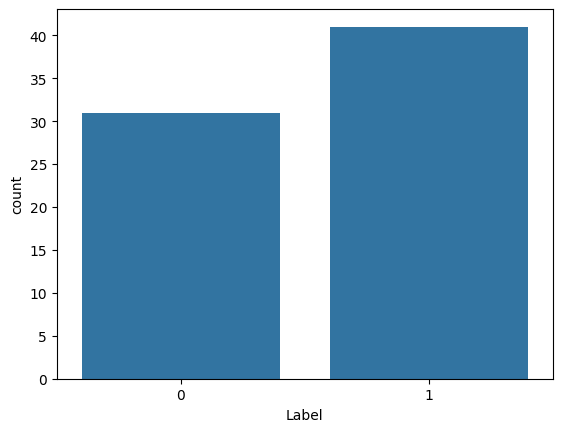

In [3]:
sns.countplot(data = Macula_df, x='Label')

[[  1 310]
 [  0 248]
 [  1 303]
 [  1 251]
 [  1 215]
 [  0 262]
 [  0 320]
 [  1 243]
 [  0 238]
 [  1 238]
 [  1 224]
 [  0 250]
 [  0 228]
 [  1 220]
 [  1 250]
 [  0 246]
 [  0 265]
 [  1 234]
 [  1 250]
 [  0 249]
 [  1 252]
 [  0 320]
 [  1 273]
 [  0 261]
 [  1 247]
 [  0 246]
 [  0 285]
 [  1 249]
 [  1 288]
 [  1 242]
 [  1 257]
 [  0 226]
 [  1 283]
 [  0 242]
 [  0 245]
 [  0 270]
 [  1 232]
 [  0 248]
 [  0 260]
 [  1 268]
 [  0 228]
 [  1 249]
 [  1 244]
 [  0 244]
 [  1 273]
 [  1 286]
 [  0 215]
 [  1 219]
 [  1 244]
 [  1 280]
 [  1 237]
 [  0 248]
 [  1 262]
 [  1 210]
 [  1 286]
 [  1 294]
 [  0 236]
 [  1 224]
 [  1 240]
 [  1 239]
 [  0 235]
 [  0 223]
 [  1 330]
 [  1 252]
 [  0 267]
 [  1 224]
 [  0 236]
 [  0 233]
 [  0 263]
 [  0 232]
 [  1 263]
 [  1 281]]


/tmp/ipykernel_855651/2522723130.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


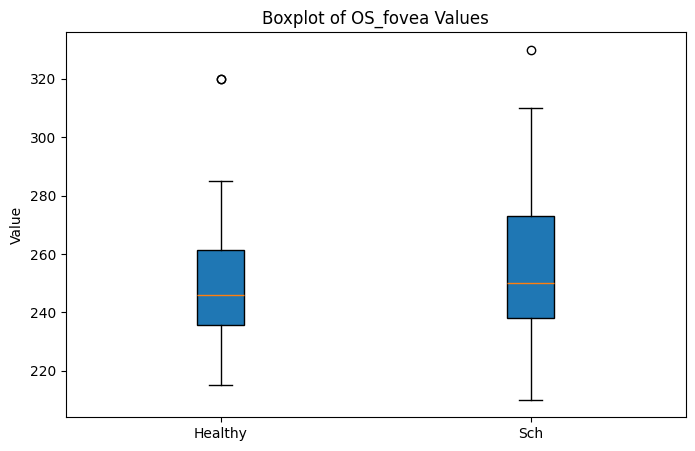

Mann–Whitney U test p-value: 0.3872911385341422


In [4]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OS_fovea = Macula_df["OS_fovea"]
# print(OD_fovea)

data = np.column_stack((Label,OS_fovea))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OS_fovea[index_0]
sch = OS_fovea[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OS_fovea Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[  1 202]
 [  0 219]
 [  1 212]
 [  1 203]
 [  1 167]
 [  0 208]
 [  0 279]
 [  1 213]
 [  0 189]
 [  1 200]
 [  1 195]
 [  0 210]
 [  0 216]
 [  1 196]
 [  1 201]
 [  0 214]
 [  0 210]
 [  1 199]
 [  1 207]
 [  0 208]
 [  1 204]
 [  0 279]
 [  1 213]
 [  0 215]
 [  1 215]
 [  0 222]
 [  0 208]
 [  1 200]
 [  1 211]
 [  1 200]
 [  1 213]
 [  0 204]
 [  1 201]
 [  0 212]
 [  0 211]
 [  0 208]
 [  1 203]
 [  0 217]
 [  0 199]
 [  1 230]
 [  0 188]
 [  1 194]
 [  1 204]
 [  0 205]
 [  1 229]
 [  1 261]
 [  0 187]
 [  1 194]
 [  1 165]
 [  1 220]
 [  1 198]
 [  0 211]
 [  1 205]
 [  1 177]
 [  1 194]
 [  1 196]
 [  0 204]
 [  1 189]
 [  1 194]
 [  1 211]
 [  0 201]
 [  0 191]
 [  1 306]
 [  1 213]
 [  0 211]
 [  1 205]
 [  0 199]
 [  0 191]
 [  0 212]
 [  0 210]
 [  1 208]
 [  1 196]]


/tmp/ipykernel_855651/2105030363.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


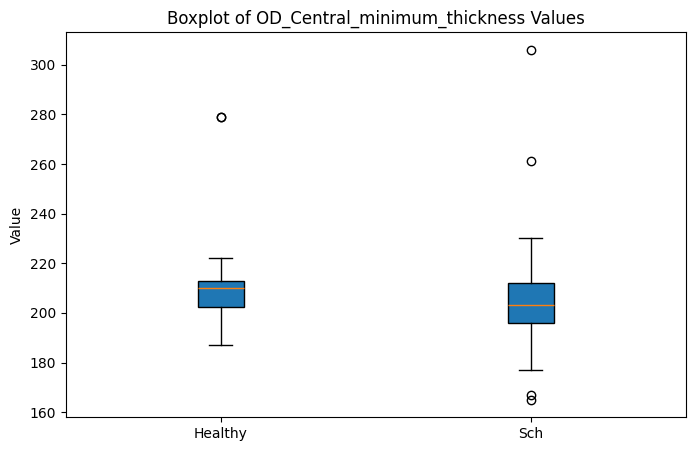

Mann–Whitney U test p-value: 0.12440060115694868


In [5]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OD_Central_minimum_thickness = Macula_df["OD_Central_minimum_thickness"]
# print(OD_fovea)

data = np.column_stack((Label,OD_Central_minimum_thickness))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OD_Central_minimum_thickness[index_0]
sch = OD_Central_minimum_thickness[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OD_Central_minimum_thickness Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[  1 330]
 [  0 326]
 [  1 354]
 [  1 340]
 [  1 308]
 [  0 365]
 [  0 345]
 [  1 332]
 [  0 324]
 [  1 311]
 [  1 314]
 [  0 334]
 [  0 308]
 [  1 325]
 [  1 323]
 [  0 329]
 [  0 344]
 [  1 323]
 [  1 314]
 [  0 324]
 [  1 334]
 [  0 345]
 [  1 353]
 [  0 345]
 [  1 317]
 [  0 317]
 [  0 335]
 [  1 344]
 [  1 327]
 [  1 309]
 [  1 358]
 [  0 320]
 [  1 343]
 [  0 328]
 [  0 324]
 [  0 318]
 [  1 314]
 [  0 335]
 [  0 353]
 [  1 323]
 [  0 329]
 [  1 326]
 [  1 338]
 [  0 339]
 [  1 325]
 [  1 340]
 [  0 314]
 [  1 309]
 [  1 307]
 [  1 331]
 [  1 291]
 [  0 346]
 [  1 303]
 [  1 266]
 [  1 315]
 [  1 354]
 [  0 331]
 [  1 343]
 [  1 324]
 [  1 326]
 [  0 317]
 [  0 320]
 [  1 332]
 [  1 323]
 [  0 344]
 [  1 300]
 [  0 325]
 [  0 324]
 [  0 338]
 [  0 303]
 [  1 313]
 [  1 302]]


/tmp/ipykernel_855651/871210018.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


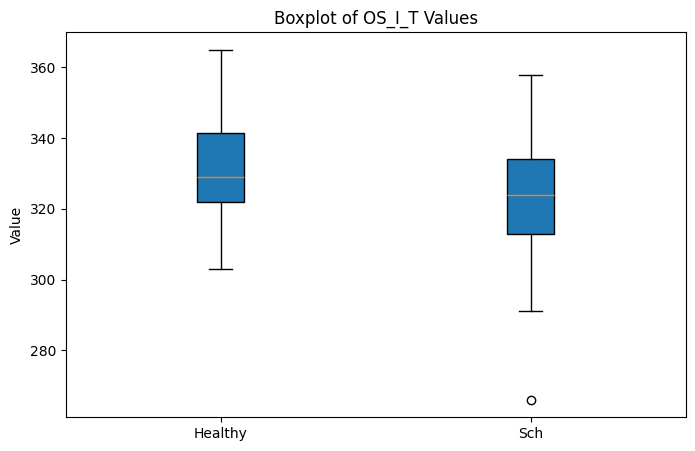

Mann–Whitney U test p-value: 0.07681403270295346


In [6]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OS_I_T = Macula_df["OS_I_T"]
# print(OD_fovea)

data = np.column_stack((Label,OS_I_T))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OS_I_T[index_0]
sch = OS_I_T[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OS_I_T Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[1.   8.24]
 [0.   8.33]
 [1.   9.08]
 [1.   8.92]
 [1.   7.91]
 [0.   9.24]
 [0.   8.68]
 [1.   8.54]
 [0.   8.43]
 [1.   8.04]
 [1.   7.5 ]
 [0.   8.71]
 [0.   8.11]
 [1.   8.47]
 [1.   8.21]
 [0.   8.59]
 [0.   8.99]
 [1.   8.43]
 [1.   8.31]
 [0.   8.11]
 [1.   8.19]
 [0.   8.68]
 [1.   9.12]
 [0.   8.73]
 [1.   8.57]
 [0.   8.33]
 [0.   8.28]
 [1.   8.47]
 [1.   8.4 ]
 [1.   8.42]
 [1.   9.06]
 [0.   8.26]
 [1.   9.07]
 [0.   8.12]
 [0.   7.97]
 [0.   8.7 ]
 [1.   8.27]
 [0.   8.33]
 [0.   8.77]
 [1.   8.63]
 [0.   8.64]
 [1.   8.09]
 [1.   8.48]
 [0.   8.65]
 [1.   8.31]
 [1.   8.45]
 [0.   8.5 ]
 [1.   7.77]
 [1.   7.95]
 [1.   8.02]
 [1.   7.98]
 [0.   8.58]
 [1.   7.84]
 [1.   7.26]
 [1.   8.06]
 [1.   8.81]
 [0.   8.62]
 [1.   8.63]
 [1.   8.02]
 [1.   8.09]
 [0.   7.83]
 [0.   8.11]
 [1.   8.42]
 [1.   8.04]
 [0.   8.54]
 [1.   8.12]
 [0.   8.23]
 [0.   8.13]
 [0.   8.35]
 [0.   8.27]
 [1.   8.01]
 [1.   8.31]]


/tmp/ipykernel_855651/2599175839.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


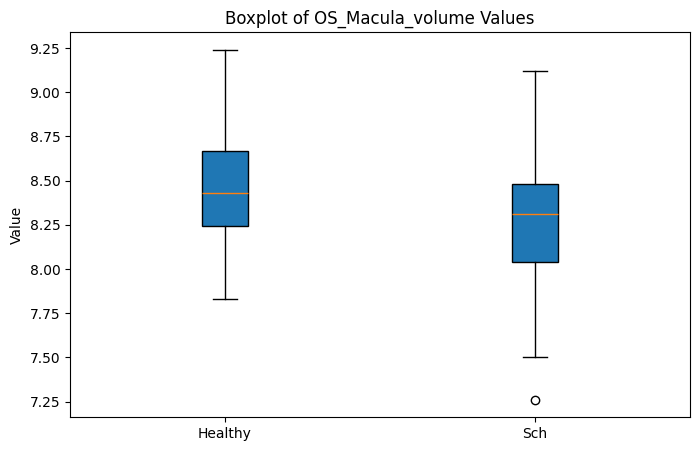

Mann–Whitney U test p-value: 0.062120178264042814


In [7]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OS_Macula_volume = Macula_df["OS_Macula_volume"]
# print(OD_fovea)

data = np.column_stack((Label,OS_Macula_volume))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OS_Macula_volume[index_0]
sch = OS_Macula_volume[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OS_Macula_volume Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[  1 217]
 [  0 213]
 [  1 220]
 [  1 203]
 [  1 167]
 [  0 209]
 [  0 268]
 [  1 212]
 [  0 190]
 [  1 198]
 [  1 193]
 [  0 212]
 [  0 210]
 [  1 194]
 [  1 203]
 [  0 203]
 [  0 208]
 [  1 189]
 [  1 206]
 [  0 212]
 [  1 207]
 [  0 268]
 [  1 215]
 [  0 211]
 [  1 210]
 [  0 224]
 [  0 206]
 [  1 199]
 [  1 210]
 [  1 199]
 [  1 212]
 [  0 202]
 [  1 199]
 [  0 214]
 [  0 208]
 [  0 208]
 [  1 206]
 [  0 210]
 [  0 201]
 [  1 223]
 [  0 191]
 [  1 193]
 [  1 207]
 [  0 206]
 [  1 236]
 [  1 242]
 [  0 194]
 [  1 195]
 [  1 170]
 [  1 236]
 [  1 199]
 [  0 211]
 [  1 201]
 [  1 188]
 [  1 201]
 [  1 196]
 [  0 209]
 [  1 191]
 [  1 193]
 [  1 209]
 [  0 193]
 [  0 196]
 [  1 260]
 [  1 208]
 [  0 210]
 [  1 204]
 [  0 198]
 [  0 184]
 [  0 210]
 [  0 208]
 [  1 202]
 [  1 198]]


/tmp/ipykernel_855651/3572970516.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


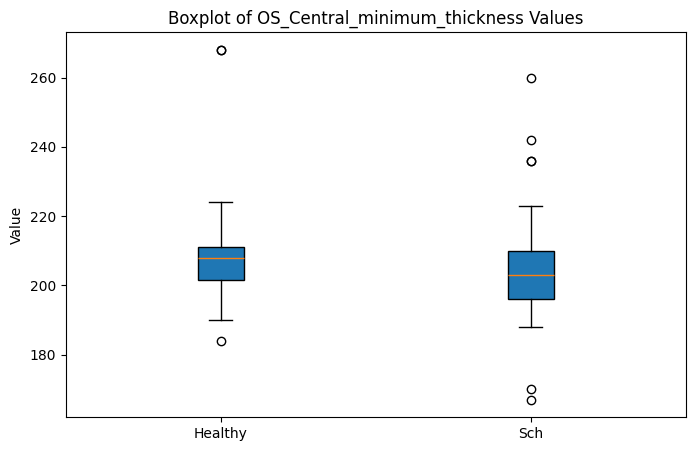

Mann–Whitney U test p-value: 0.18478439408767822


In [8]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OS_Central_minimum_thickness = Macula_df["OS_Central_minimum_thickness"]
# print(OD_fovea)

data = np.column_stack((Label,OS_Central_minimum_thickness))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OS_Central_minimum_thickness[index_0]
sch = OS_Central_minimum_thickness[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OS_Central_minimum_thickness Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[  1 298]
 [  0 254]
 [  1 243]
 [  1 247]
 [  1 202]
 [  0 263]
 [  0 313]
 [  1 243]
 [  0 237]
 [  1 241]
 [  1 230]
 [  0 251]
 [  0 281]
 [  1 224]
 [  1 239]
 [  0 258]
 [  0 256]
 [  1 238]
 [  1 246]
 [  0 259]
 [  1 244]
 [  0 313]
 [  1 274]
 [  0 284]
 [  1 257]
 [  0 245]
 [  0 234]
 [  1 247]
 [  1 294]
 [  1 236]
 [  1 278]
 [  0 226]
 [  1 276]
 [  0 240]
 [  0 251]
 [  0 250]
 [  1 226]
 [  0 260]
 [  0 252]
 [  1 263]
 [  0 226]
 [  1 239]
 [  1 241]
 [  0 240]
 [  1 273]
 [  1 338]
 [  0 201]
 [  1 216]
 [  1 189]
 [  1 264]
 [  1 239]
 [  0 251]
 [  1 240]
 [  1 204]
 [  1 257]
 [  1 309]
 [  0 246]
 [  1 220]
 [  1 237]
 [  1 243]
 [  0 229]
 [  0 218]
 [  1 329]
 [  1 254]
 [  0 275]
 [  1 227]
 [  0 232]
 [  0 252]
 [  0 251]
 [  0 230]
 [  1 242]
 [  1 251]]


/tmp/ipykernel_855651/1343490781.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


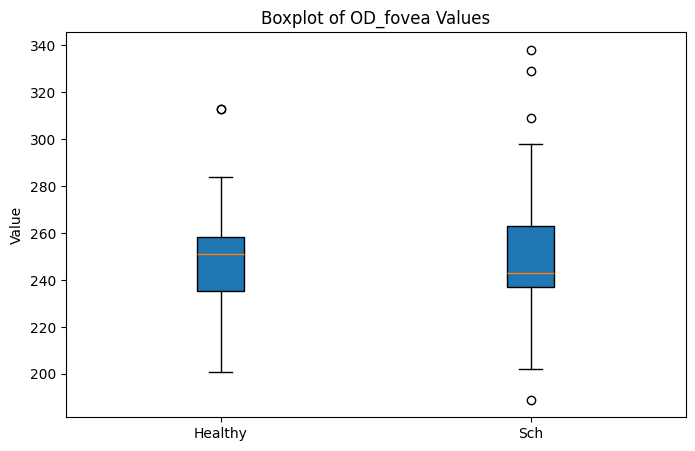

Mann–Whitney U test p-value: 0.5656130128499498


In [9]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OD_fovea = Macula_df["OD_fovea"]
# print(OD_fovea)

data = np.column_stack((Label,OD_fovea))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OD_fovea[index_0]
sch = OD_fovea[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OD_fovea Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[1.   0.23]
 [0.   0.2 ]
 [1.   0.19]
 [1.   0.19]
 [1.   0.16]
 [0.   0.21]
 [0.   0.25]
 [1.   0.19]
 [0.   0.19]
 [1.   0.19]
 [1.   0.18]
 [0.   0.2 ]
 [0.   0.22]
 [1.   0.18]
 [1.   0.19]
 [0.   0.2 ]
 [0.   0.2 ]
 [1.   0.19]
 [1.   0.19]
 [0.   0.2 ]
 [1.   0.19]
 [0.   0.25]
 [1.   0.22]
 [0.   0.22]
 [1.   0.2 ]
 [0.   0.19]
 [0.   0.18]
 [1.   0.19]
 [1.   0.23]
 [1.   0.18]
 [1.   0.22]
 [0.   0.18]
 [1.   0.22]
 [0.   0.19]
 [0.   0.2 ]
 [0.   0.2 ]
 [1.   0.18]
 [0.   0.2 ]
 [0.   0.2 ]
 [1.   0.21]
 [0.   0.18]
 [1.   0.19]
 [1.   0.19]
 [0.   0.19]
 [1.   0.21]
 [1.   0.27]
 [0.   0.16]
 [1.   0.17]
 [1.   0.15]
 [1.   0.1 ]
 [1.   0.19]
 [0.   0.2 ]
 [1.   0.19]
 [1.   0.16]
 [1.   0.2 ]
 [1.   0.24]
 [0.   0.19]
 [1.   0.17]
 [1.   0.19]
 [1.   0.19]
 [0.   0.18]
 [0.   0.17]
 [1.   0.26]
 [1.   0.2 ]
 [0.   0.22]
 [1.   0.18]
 [0.   0.18]
 [0.   0.2 ]
 [0.   0.2 ]
 [0.   0.18]
 [1.   0.19]
 [1.   0.2 ]]


/tmp/ipykernel_855651/1614541518.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


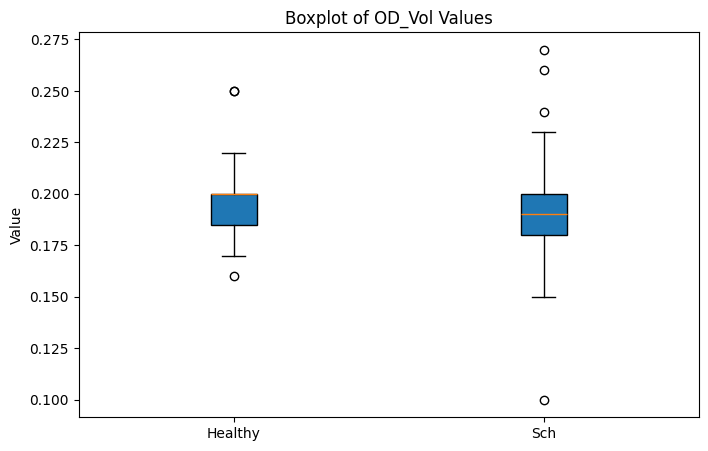

Mann–Whitney U test p-value: 0.35612853781232146


In [10]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OD_Vol = Macula_df["OD_Vol "]
# print(OD_fovea)

data = np.column_stack((Label,OD_Vol))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OD_Vol[index_0]
sch = OD_Vol[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OD_Vol Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

[[  1 342]
 [  0 294]
 [  1 356]
 [  1 311]
 [  1 294]
 [  0 327]
 [  0 356]
 [  1 295]
 [  0 290]
 [  1 283]
 [  1 285]
 [  0 293]
 [  0 265]
 [  1 271]
 [  1 313]
 [  0 293]
 [  0 338]
 [  1 284]
 [  1 308]
 [  0 304]
 [  1 314]
 [  0 356]
 [  1 321]
 [  0 308]
 [  1 286]
 [  0 281]
 [  0 343]
 [  1 327]
 [  1 336]
 [  1 313]
 [  1 310]
 [  0 264]
 [  1 354]
 [  0 283]
 [  0 311]
 [  0 337]
 [  1 270]
 [  0 293]
 [  0 324]
 [  1 326]
 [  0 271]
 [  1 310]
 [  1 298]
 [  0 299]
 [  1 305]
 [  1 336]
 [  0 253]
 [  1 265]
 [  1 306]
 [  1 326]
 [  1 267]
 [  0 294]
 [  1 327]
 [  1 238]
 [  1 324]
 [  1 355]
 [  0 285]
 [  1 295]
 [  1 301]
 [  1 285]
 [  0 293]
 [  0 258]
 [  1 347]
 [  1 298]
 [  0 316]
 [  1 256]
 [  0 295]
 [  0 309]
 [  0 335]
 [  0 270]
 [  1 310]
 [  1 337]]


/tmp/ipykernel_855651/3288511144.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([healthy, sch],


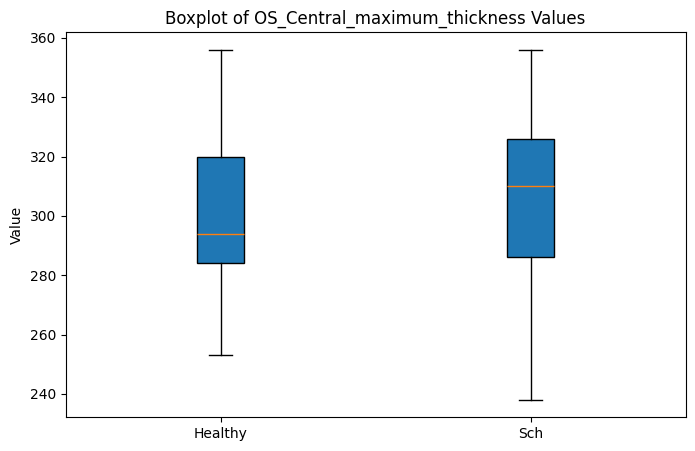

Mann–Whitney U test p-value: 0.2600405449578206


In [11]:
from scipy.stats import mannwhitneyu

Label = Macula_df["Label"]
# print(Label)

OS_Central_maximum_thickness = Macula_df["OS_Central_maximum_thickness"]
# print(OD_fovea)

data = np.column_stack((Label,OS_Central_maximum_thickness))
print(data)

index_0 = np.where(Label==0)[0]
# print(index_0)

index_1 = np.where(Label==1)[0]
# print(index_1)


healthy = OS_Central_maximum_thickness[index_0]
sch = OS_Central_maximum_thickness[index_1]

plt.figure(figsize=(8, 5))

plt.boxplot([healthy, sch],
            labels=['Healthy', 'Sch'],
            patch_artist=True)

plt.title("Boxplot of OS_Central_maximum_thickness Values")
plt.ylabel("Value")

plt.show()


stat, pvalue = mannwhitneyu(healthy, sch, alternative='two-sided')
print("Mann–Whitney U test p-value:", pvalue)

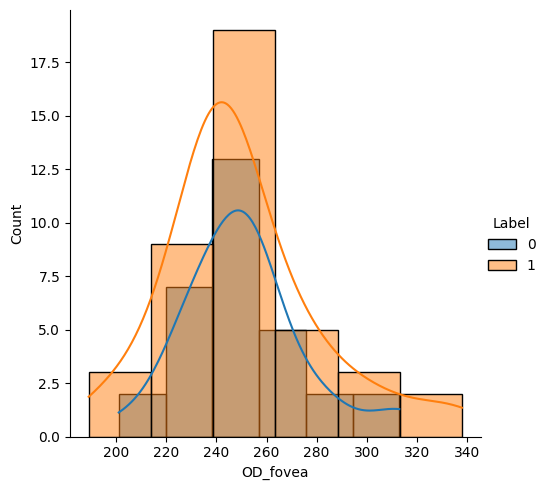

In [12]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_fovea", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

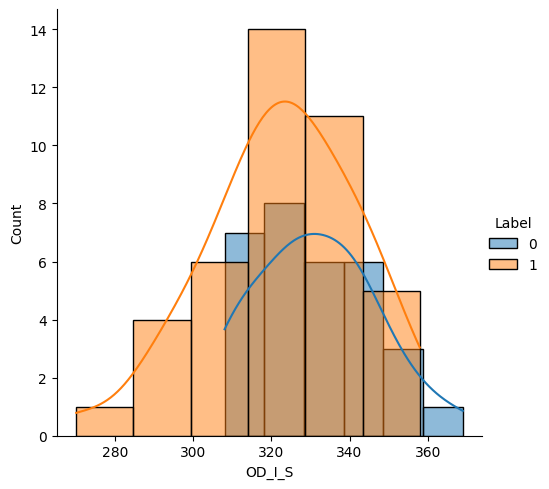

In [13]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

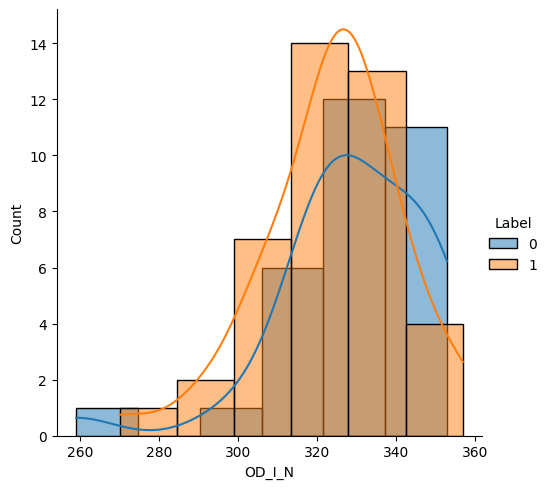

In [14]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

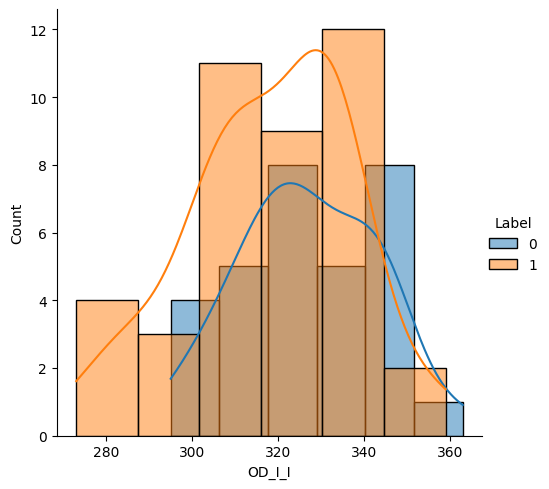

In [15]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

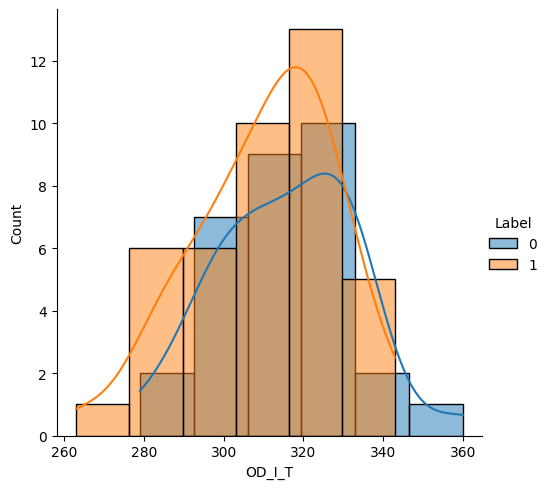

In [16]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

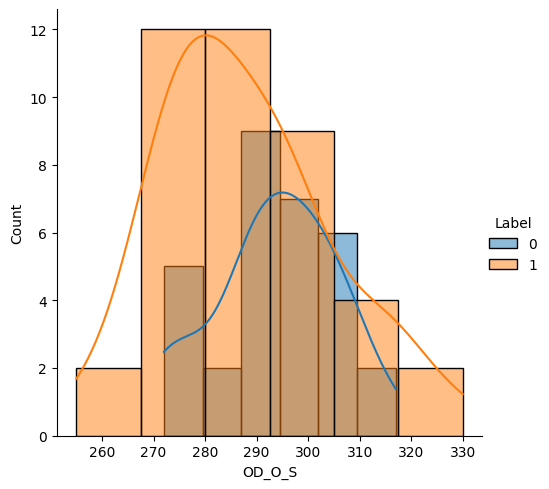

In [17]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

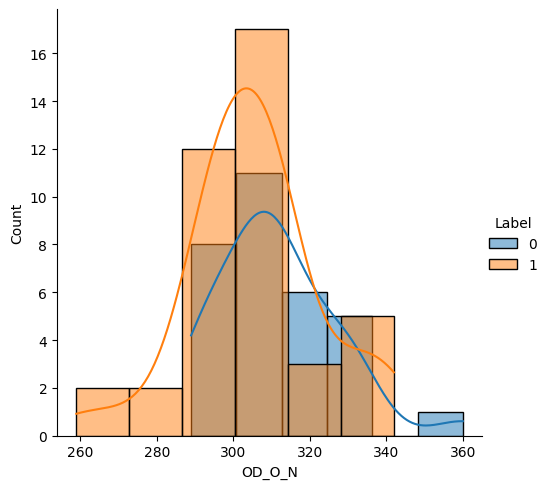

In [18]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

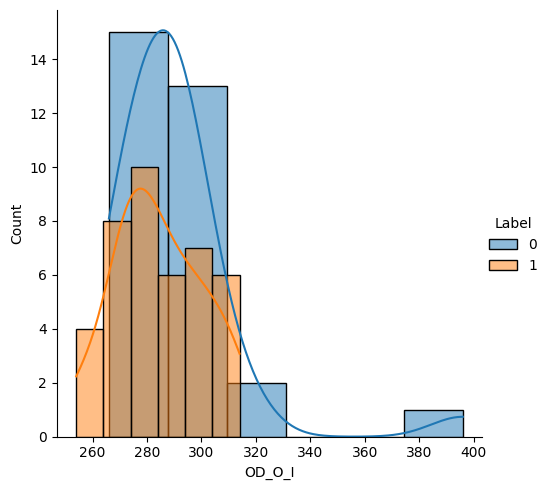

In [19]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

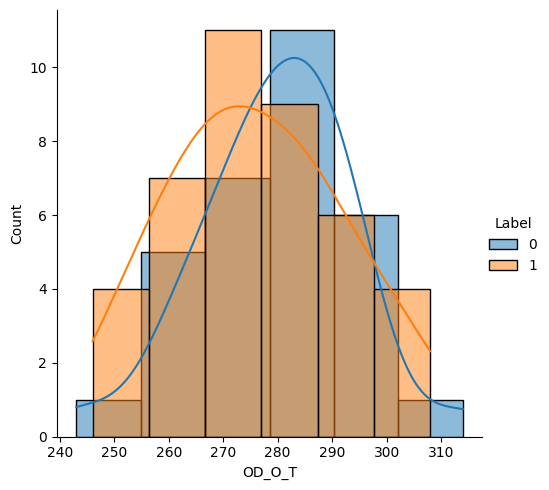

In [20]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

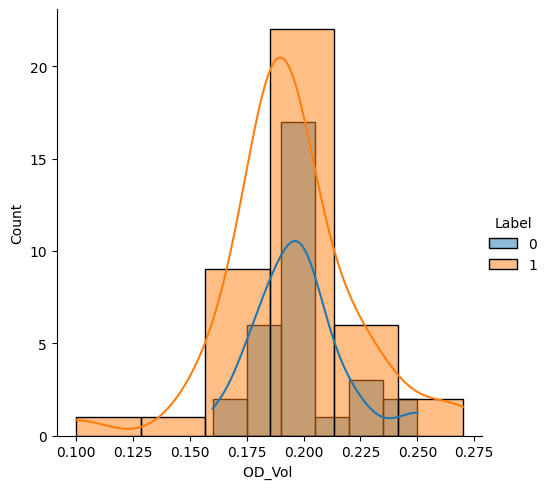

In [21]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Vol ", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

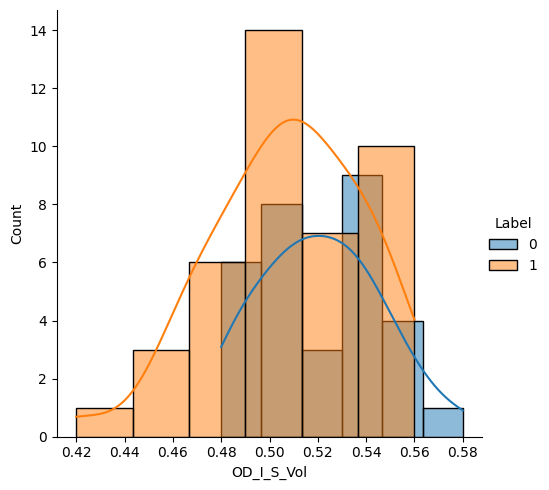

In [22]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

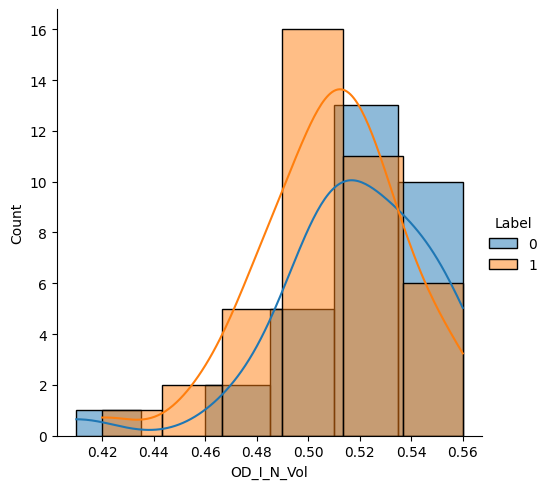

In [23]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

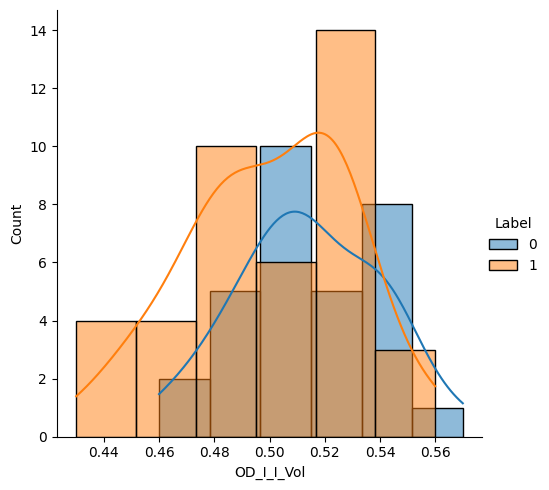

In [24]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

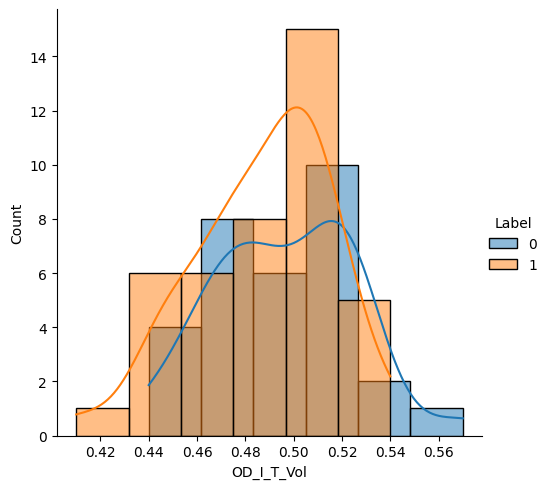

In [25]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_I_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

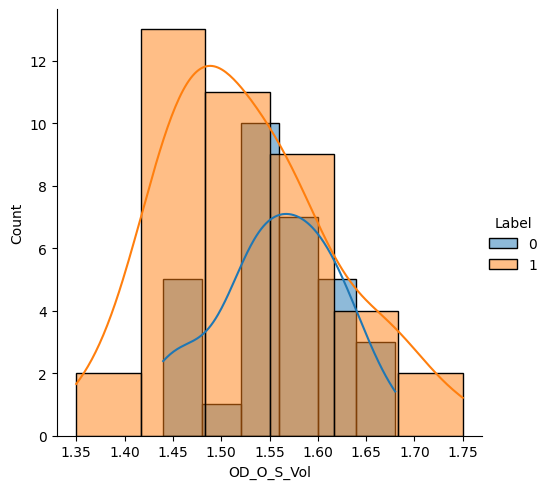

In [26]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

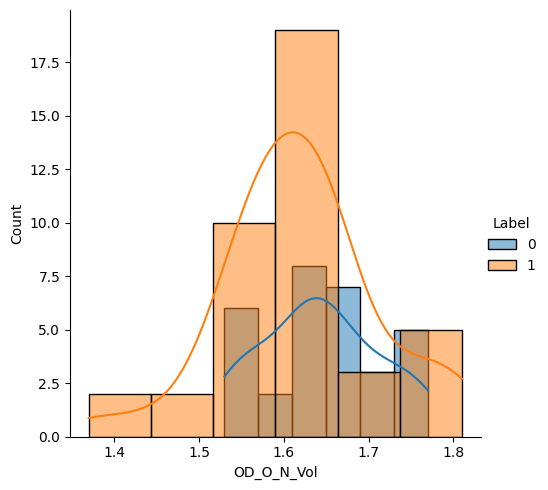

In [27]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

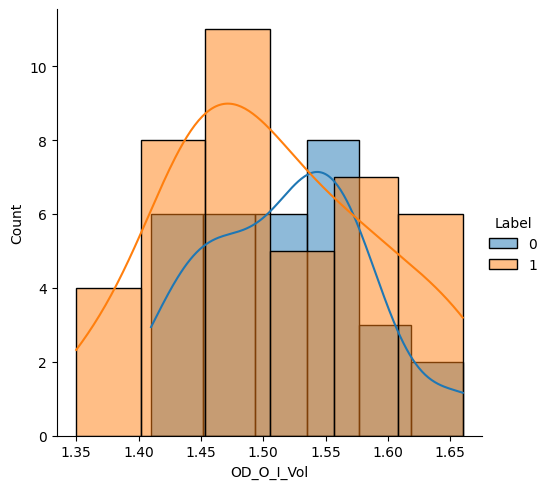

In [28]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

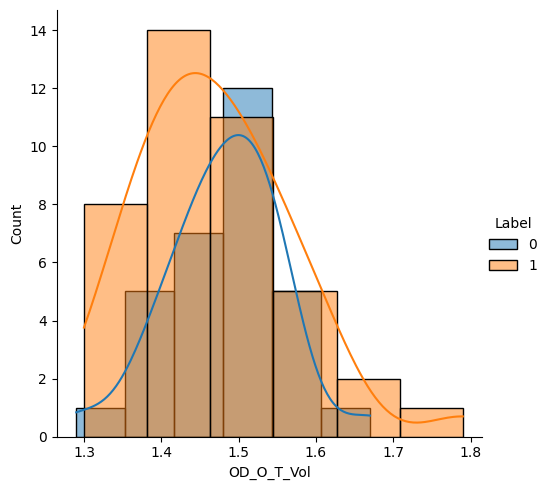

In [29]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_O_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

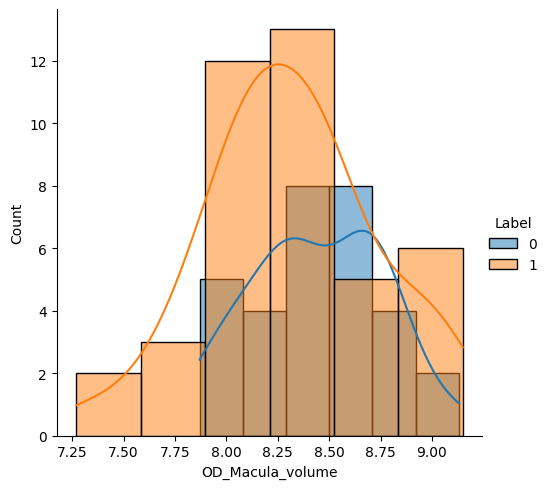

In [30]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Macula_volume", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

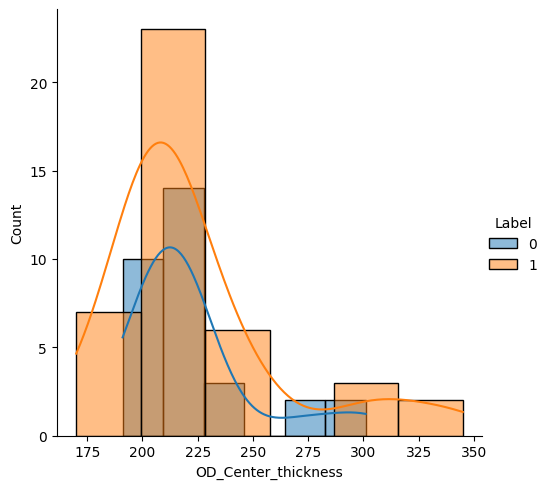

In [31]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Center_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

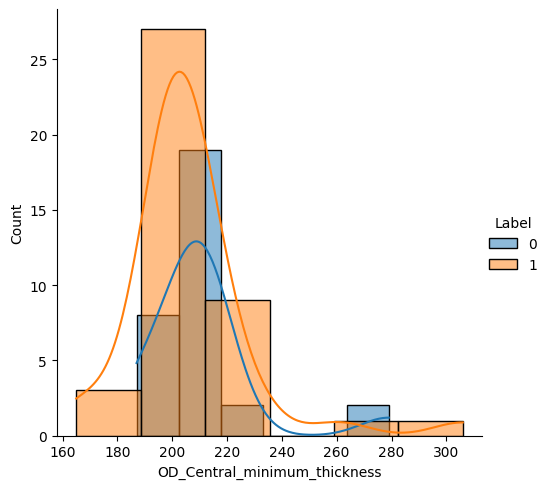

In [32]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Central_minimum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

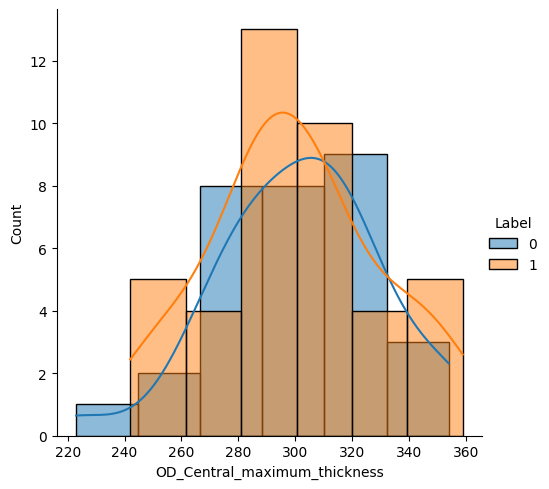

In [33]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OD_Central_maximum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

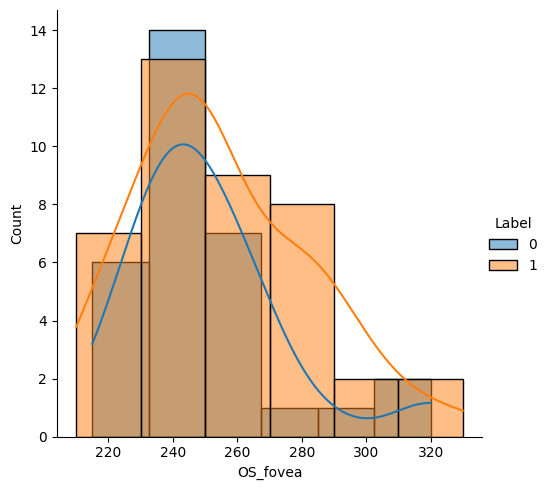

In [34]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_fovea", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

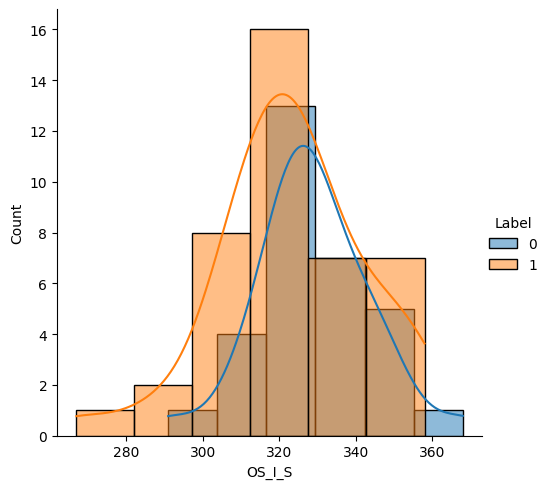

In [35]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

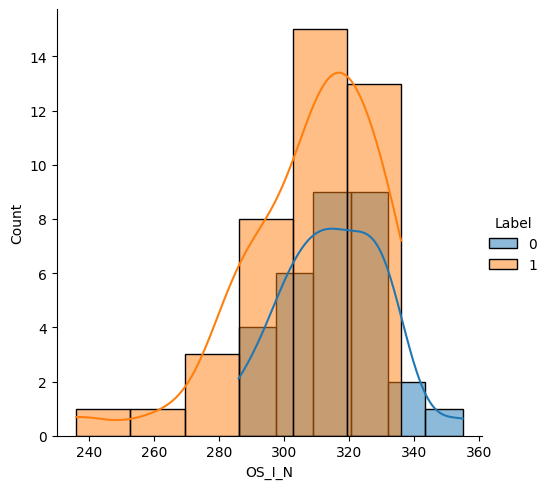

In [36]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

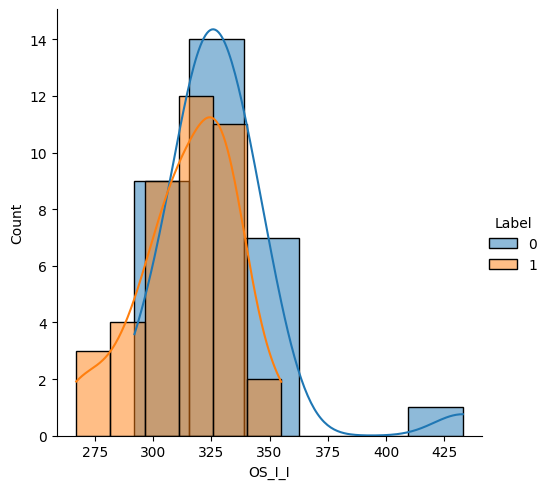

In [37]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

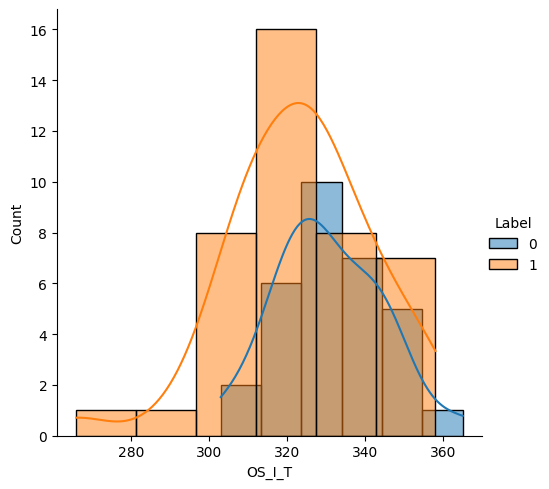

In [38]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

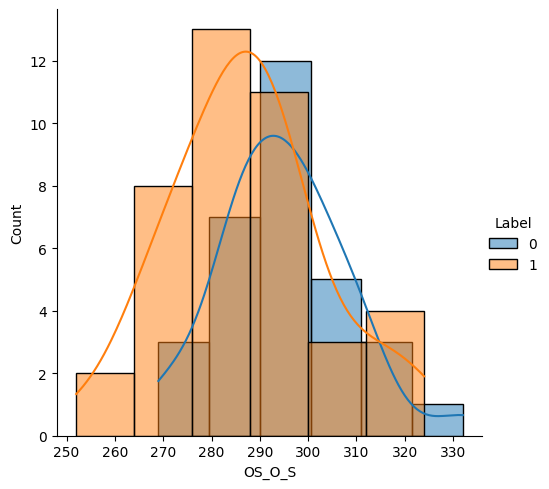

In [39]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_S", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

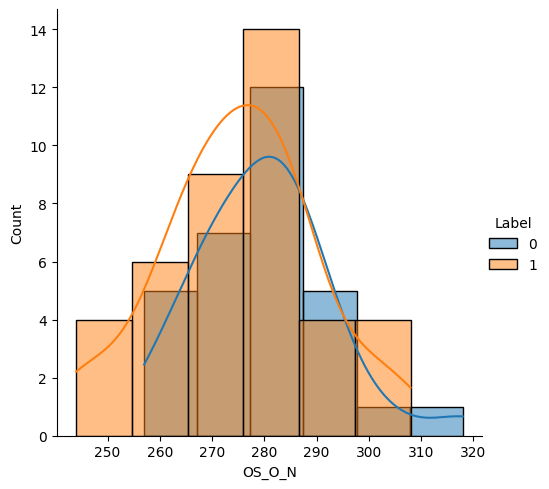

In [40]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_N", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

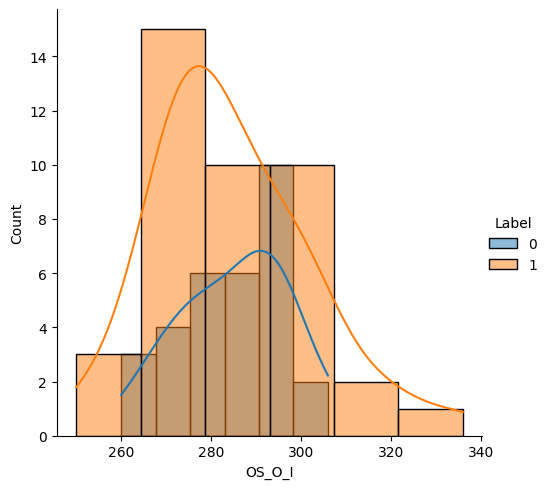

In [41]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_I", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

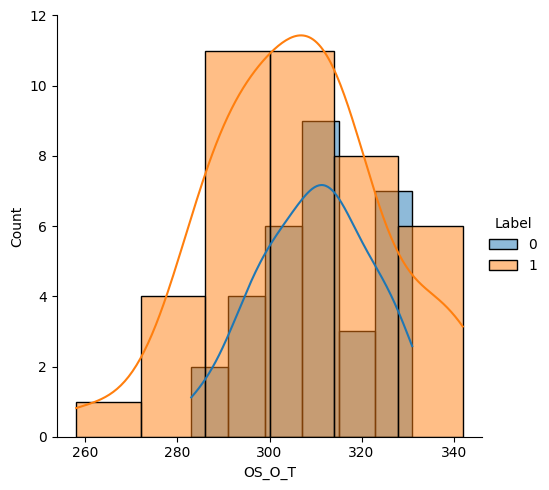

In [42]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_T", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

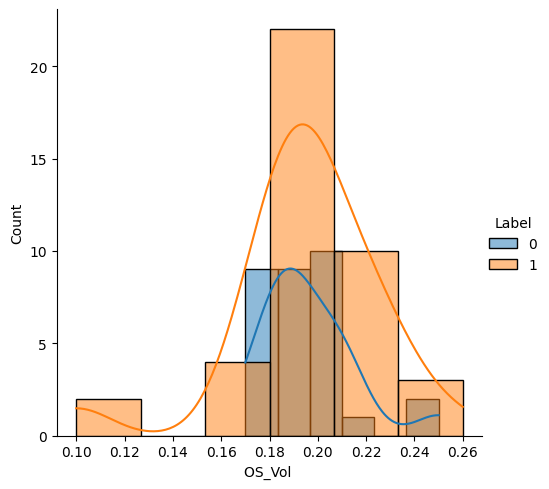

In [43]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Vol ", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

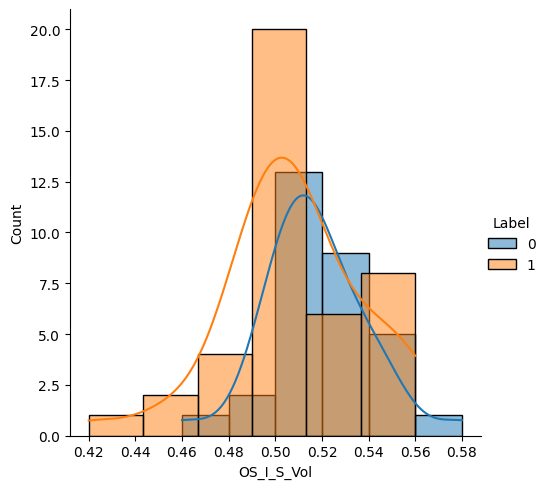

In [44]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

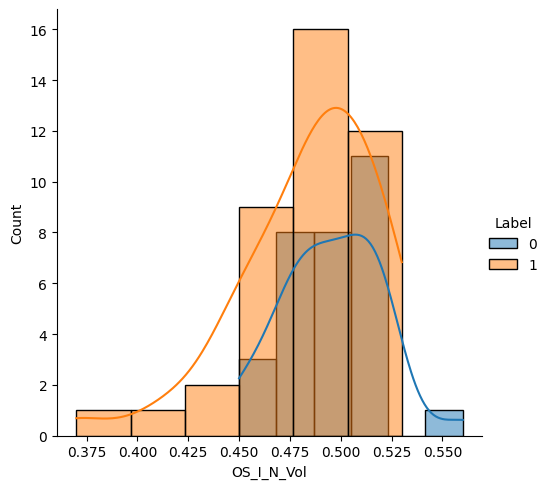

In [45]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

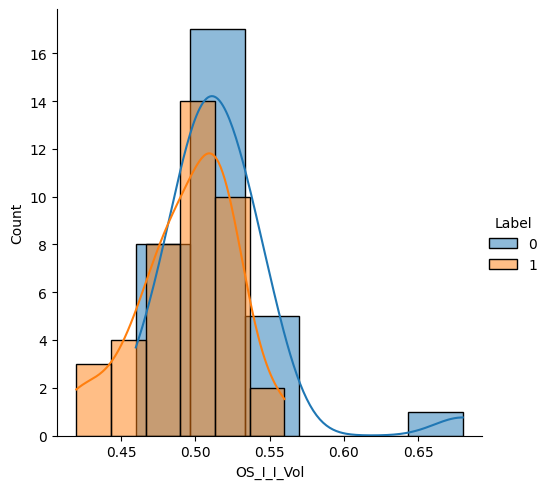

In [46]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

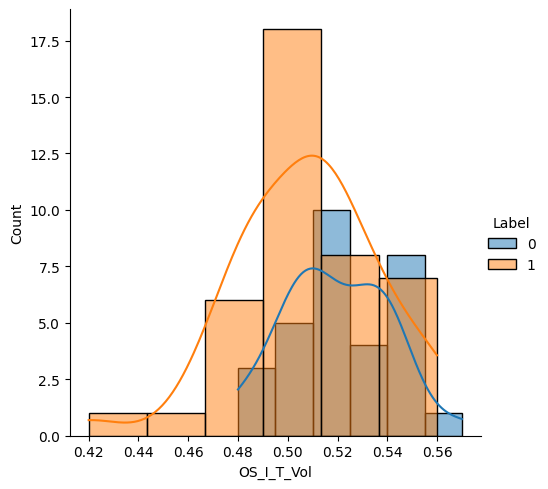

In [47]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_I_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

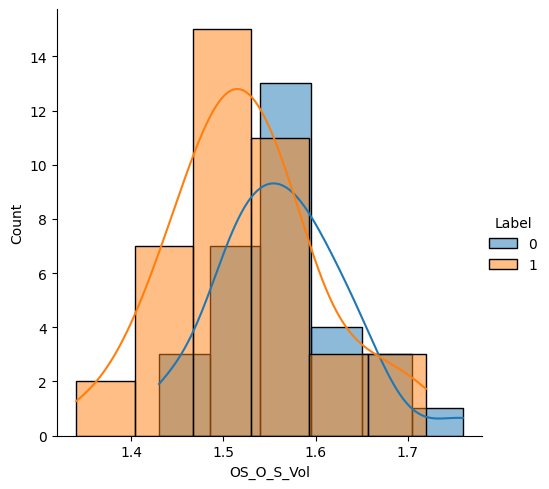

In [48]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_S_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

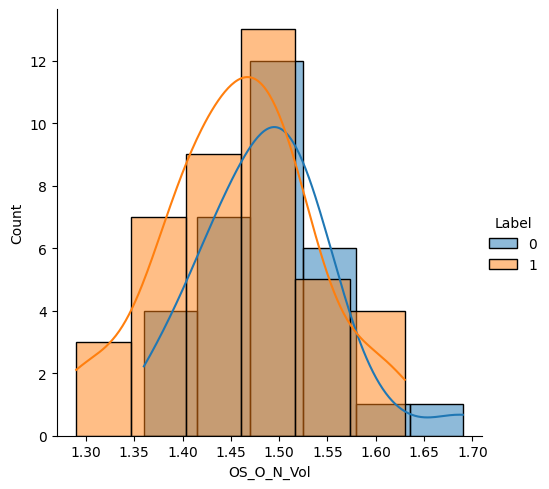

In [49]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_N_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

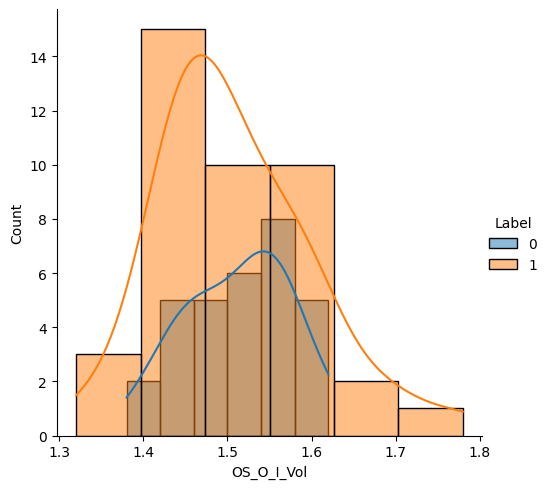

In [50]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_I_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

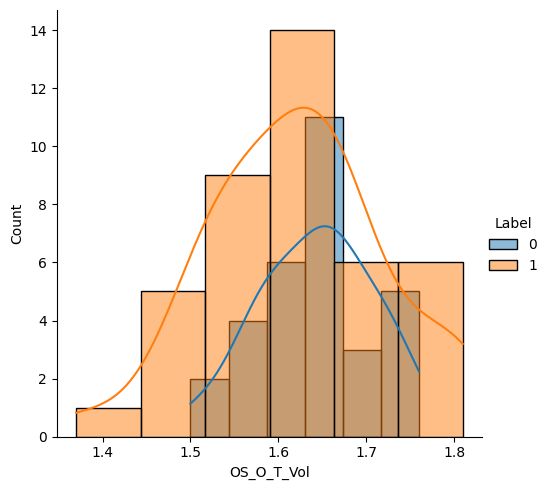

In [51]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_O_T_Vol", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

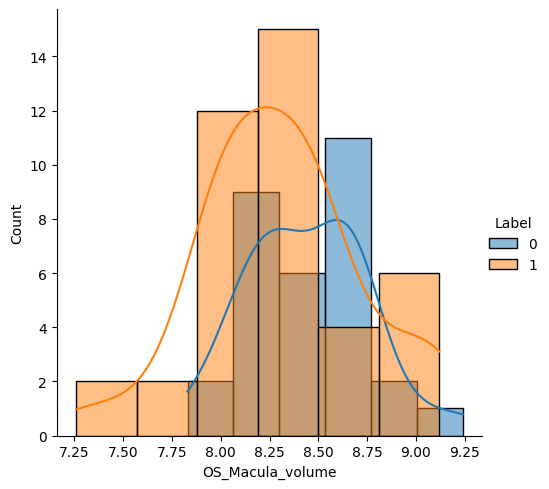

In [52]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Macula_volume", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

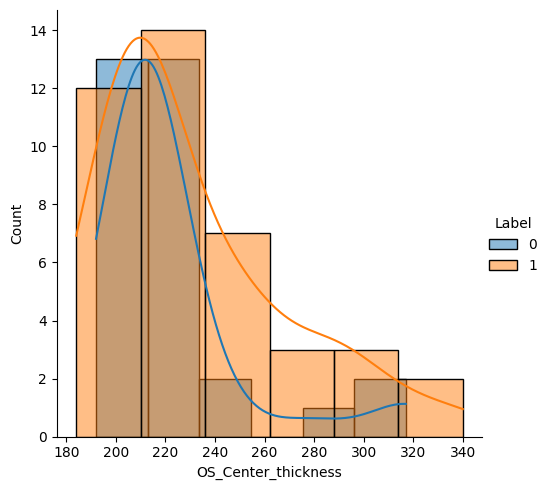

In [53]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Center_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

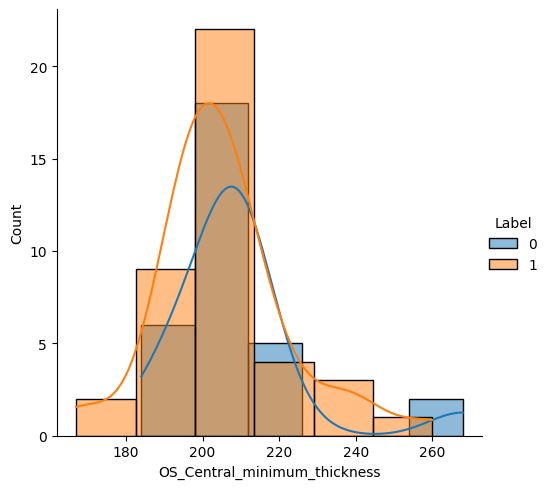

In [54]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Central_minimum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

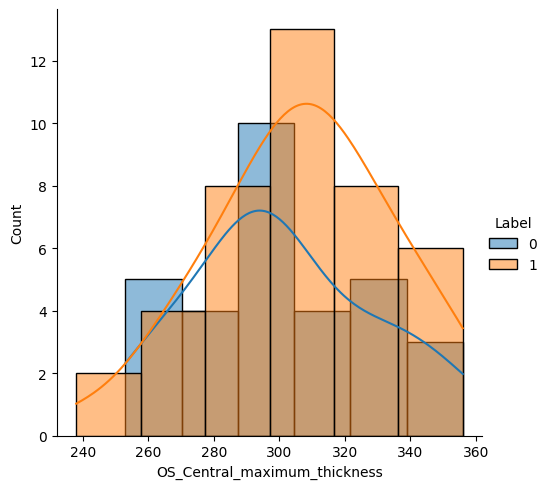

In [55]:
sns.FacetGrid(Macula_df, hue="Label", height=5).map(sns.histplot, "OS_Central_maximum_thickness", stat="count", kde=True, bins=6, alpha=0.5).add_legend()

In [3]:
# X = iris_skl.data  # Features
# y = iris_skl.target  # Labels

Macula = np.array(Macula_df)
X = Macula[:,1:-1]  # Features
y = Macula[:,-1]  # Labels

y = np.array(y, dtype=np.uint8)
print(X)
print(y)

[[298 310 328 ... 319 217 342]
 [254 335 330 ... 218 213 294]
 [243 343 341 ... 300 220 356]
 ...
 [230 312 308 ... 219 208 270]
 [242 314 313 ... 251 202 310]
 [251 334 338 ... 277 198 337]]
[1 0 1 1 1 0 0 1 0 1 1 0 0 1 1 0 0 1 1 0 1 0 1 0 1 0 0 1 1 1 1 0 1 0 0 0 1
 0 0 1 0 1 1 0 1 1 0 1 1 1 1 0 1 1 1 1 0 1 1 1 0 0 1 1 0 1 0 0 0 0 1 1]


In [4]:
# param_grid = {
#     'hidden_layer_sizes':[
#         (32,),
#         (64,),
#         (64,32),
#         (128,64)
#     ],
#     'activation':['relu','tanh'],
#     'alpha':[1e-5,1e-4,1e-3],
#     'learning_rate_init':[0.001,0.0005],
#     'batch_size':[16,32,64]
# }

# mlp = MLPClassifier(
#             solver="adam",
#             max_iter=500,
#             random_state=42
#       )

# cv = StratifiedKFold(
#     n_splits=5,
#     shuffle=True,
#     random_state=42
# )

# grid = GridSearchCV(
#     estimator=mlp,
#     param_grid=param_grid,
#     scoring='roc_auc',
#     cv=cv,
#     n_jobs=-1,
#     return_train_score=True,
#     verbose=2
# )

# grid.fit(X, y)

In [5]:
# print("Best Parameters")
# print(grid.best_params_)

# print("\nBest CV AUC")
# print(grid.best_score_)

In [4]:
def Normalize(arr):
    # Compute min and max for each column
    col_min = arr.min(axis=0)  # Minimum of each column
    col_max = arr.max(axis=0)  # Maximum of each column
    
    # Avoid division by zero (if all values in a column are the same)
    col_range = col_max - col_min
    col_range[col_range == 0] = 1  # Prevent division by zero
    
    # Normalize using broadcasting
    normalized_arr = (arr - col_min) / col_range

    return normalized_arr

def Oversample(arr,num_samp):
    # Number of rows to sample
    num_samples = num_samp 
    
    # Randomly select row indices
    random_indices = np.random.choice(arr.shape[0], num_samples, replace=True)  # replace=True allows duplicates
    
    # Extract the selected rows
    random_rows = arr[random_indices]
    
    # Append the selected rows to the original array
    new_arr = np.vstack((arr, random_rows))
    
    return new_arr



def train_test_split_custom(X, y):
    # X = Normalize(X)
    c_array_new = np.column_stack((X,y))

    # Extract the diagnosis column (last column)
    outcome = c_array_new[:, -1]

    c_array_new_0 = c_array_new[outcome == 0]  # Rows where species is 0
    c_array_new_1 = c_array_new[outcome == 1]  # Rows where species is 1

    np.random.shuffle(c_array_new_0)
    np.random.shuffle(c_array_new_1)

    # train test split
    split_len = int(0.7*len(c_array_new_0))
    c_array_new_0_train = c_array_new_0[0:split_len,:]
    c_array_new_0_test =  c_array_new_0[split_len:,:]

    split_len = int(0.7*len(c_array_new_1))
    c_array_new_1_train = c_array_new_1[0:split_len,:]
    c_array_new_1_test =  c_array_new_1[split_len:,:]


    # print(len(c_array_new_0_train),len(c_array_new_0_test))
    # print(len(c_array_new_1_train),len(c_array_new_1_test))

    # oversample
    if False:
        c_array_new_1_train = Oversample(c_array_new_1_train,len(c_array_new_0_train)-len(c_array_new_1_train))

        print(len(c_array_new_0_train),len(c_array_new_0_test))
        print(len(c_array_new_1_train),len(c_array_new_1_test))

    
    # combine
    train = np.concatenate((c_array_new_0_train,c_array_new_1_train), axis = 0)
    test  = np.concatenate((c_array_new_0_test, c_array_new_1_test), axis = 0)
    np.random.shuffle(train)
    np.random.shuffle(test)

    # split
    X_train = train[:,0:-1]
    y_train = train[:,-1]

    X_test = test[:,0:-1]
    y_test = test[:,-1]

    y_train = y_train.astype(int)
    y_test = y_test.astype(int)

    return X_train, X_test, y_train, y_test

In [5]:
feature_names = ['OD_fovea', 'OD_I_S', 'OD_I_N', 'OD_I_I', 'OD_I_T', 'OD_O_S', 'OD_O_N', 'OD_O_I', 'OD_O_T', 'OD_Vol ', 'OD_I_S_Vol', 'OD_I_N_Vol', 'OD_I_I_Vol',
                 'OD_I_T_Vol', 'OD_O_S_Vol', 'OD_O_N_Vol', 'OD_O_I_Vol', 'OD_O_T_Vol', 'OD_Macula_volume', 'OD_Center_thickness', 'OD_Central_minimum_thickness',
                 'OD_Central_maximum_thickness', 'OS_fovea', 'OS_I_S', 'OS_I_N', 'OS_I_I', 'OS_I_T', 'OS_O_S', 'OS_O_N', 'OS_O_I', 'OS_O_T', 'OS_Vol ', 'OS_I_S_Vol',
                 'OS_I_N_Vol', 'OS_I_I_Vol', 'OS_I_T_Vol', 'OS_O_S_Vol', 'OS_O_N_Vol', 'OS_O_I_Vol', 'OS_O_T_Vol', 'OS_Macula_volume', 'OS_Center_thickness',
                 'OS_Central_minimum_thickness', 'OS_Central_maximum_thickness']

In [8]:
# # =====================================================
# # Hyperparameter Grid
# # =====================================================

# param_grid = {
#     "hidden_layer_sizes": [
#         (32,),
#         (64,),
#         (64, 32),
#         (128, 64),
#         (128, 64, 32)
#     ],
#     "activation": ["relu", "tanh"],
#     "alpha": [1e-5, 1e-4, 1e-3, 1e-2],
#     "learning_rate_init": [0.001, 0.0005],
#     "batch_size": [16, 32, 64]
# }

# # =====================================================
# # Initialization
# # =====================================================

# best_auc = -1
# best_model = None
# best_params = None

# X_train_best = None
# X_test_best = None
# y_train_best = None
# y_test_best = None

# all_best_params = []
# all_grid_results = []

# mean_fpr = np.linspace(0, 1, 100)
# mean_recall = np.linspace(0, 1, 100)

# tprs = []
# precisions = []

# aucs = []
# aps = []
# accs = []
# thresholds_all = []

# # =====================================================
# # Monte Carlo Cross Validation
# # =====================================================

# N_ITER = 1000

# for mci in range(N_ITER):

#     print(f"Iteration {mci+1}/{N_ITER}", end="\r")

#     # ---------------------------------------------
#     # Outer split
#     # ---------------------------------------------
#     X_train, X_test, y_train, y_test = train_test_split_custom(X, y)

#     # ---------------------------------------------
#     # Inner CV
#     # ---------------------------------------------
#     inner_cv = StratifiedKFold(
#         n_splits=5,
#         shuffle=True,
#         random_state=mci
#     )

#     grid = GridSearchCV(
#         estimator=MLPClassifier(
#             solver="adam",
#             max_iter=500,
#             random_state=42
#         ),
#         param_grid=param_grid,
#         scoring="roc_auc",
#         cv=inner_cv,
#         n_jobs=-1,
#         refit=True,
#         return_train_score=True
#     )

#     grid.fit(X_train, y_train)

#     model = grid.best_estimator_

#     # ---------------------------------------------
#     # Save COMPLETE GridSearch results
#     # ---------------------------------------------

#     cv_df = pd.DataFrame(grid.cv_results_)
#     cv_df["Iteration"] = mci
#     all_grid_results.append(cv_df)

#     # ---------------------------------------------
#     # Test evaluation
#     # ---------------------------------------------

#     y_prob = model.predict_proba(X_test)[:, 1]

#     # ROC

#     fpr, tpr, thresholds = roc_curve(y_test, y_prob)

#     roc_auc = auc(fpr, tpr)

#     # Optimal Threshold

#     idx = np.argmax(tpr - fpr)
#     threshold = thresholds[idx]

#     y_pred = (y_prob >= threshold).astype(int)

#     acc = accuracy_score(y_test, y_pred)

#     # Precision-Recall

#     precision, recall, _ = precision_recall_curve(y_test, y_prob)

#     ap = average_precision_score(y_test, y_prob)

#     # ---------------------------------------------
#     # Interpolation
#     # ---------------------------------------------

#     interp_tpr = np.interp(mean_fpr, fpr, tpr)
#     interp_tpr[0] = 0

#     interp_precision = np.interp(
#         mean_recall,
#         recall[::-1],
#         precision[::-1]
#     )

#     # ---------------------------------------------
#     # Store metrics
#     # ---------------------------------------------

#     tprs.append(interp_tpr)
#     precisions.append(interp_precision)

#     aucs.append(roc_auc)
#     aps.append(ap)
#     accs.append(acc)
#     thresholds_all.append(threshold)

#     # ---------------------------------------------
#     # Store Best Params
#     # ---------------------------------------------

#     params = grid.best_params_

#     row = {
#         "Iteration": mci,
#         "CV_AUC": grid.best_score_,
#         "Test_AUC": roc_auc,
#         "Accuracy": acc,
#         "AveragePrecision": ap,
#         "Threshold": threshold,
#         **params
#     }

#     all_best_params.append(row)

#     # ---------------------------------------------
#     # Best Model
#     # ---------------------------------------------

#     if roc_auc > best_auc:

#         best_auc = roc_auc
#         best_model = model
#         best_params = params

#         X_train_best = X_train.copy()
#         X_test_best = X_test.copy()
#         y_train_best = y_train.copy()
#         y_test_best = y_test.copy()

# # =====================================================
# # Save Results
# # =====================================================

# params_df = pd.DataFrame(all_best_params)

# params_df.to_csv(
#     "Best_Hyperparameters_AllIterations.csv",
#     index=False
# )

# grid_df = pd.concat(
#     all_grid_results,
#     ignore_index=True
# )

# grid_df.to_csv(
#     "Complete_GridSearch_Results.csv",
#     index=False
# )

# # =====================================================
# # Aggregate Metrics
# # =====================================================

# tprs = np.array(tprs)
# precisions = np.array(precisions)

# mean_tpr = np.mean(tprs, axis=0)
# std_tpr = np.std(tprs, axis=0)

# mean_tpr[-1] = 1

# mean_precision = np.mean(precisions, axis=0)
# std_precision = np.std(precisions, axis=0)

# print("\n")
# print("="*60)

# print(f"Mean ROC AUC : {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")
# print(f"Mean AP      : {np.mean(aps):.4f} ± {np.std(aps):.4f}")
# print(f"Mean Acc     : {np.mean(accs):.4f} ± {np.std(accs):.4f}")

# print(f"\nMedian Threshold : {np.median(thresholds_all):.4f}")
# print(f"Mean Threshold   : {np.mean(thresholds_all):.4f}")

# print("\nBest Test AUC :", best_auc)

# print("\nBest Hyperparameters")
# print(best_params)

# # =====================================================
# # Most Frequently Selected Hyperparameters
# # =====================================================

# # print("\n")
# # print("="*60)
# # print("Top Hyperparameter Combinations\n")

# freq = (
#     params_df
#     .groupby([
#         "hidden_layer_sizes",
#         "activation",
#         "alpha",
#         "learning_rate_init",
#         "batch_size"
#     ])
#     .size()
#     .sort_values(ascending=False)
# )

# print(freq.head(10))

# # =====================================================
# # SHAP ONLY FOR THE BEST MODEL
# # =====================================================

# # print("\nComputing SHAP for best model...\n")

# background = X_train_best[
#     np.random.choice(
#         X_train_best.shape[0],
#         min(20, X_train_best.shape[0]),
#         replace=False
#     )
# ]

# def predict_prob(x):
#     return best_model.predict_proba(x)[:, 1]

# explainer = shap.KernelExplainer(
#     predict_prob,
#     background
# )

# shap_values = explainer.shap_values(
#     X_test_best,
#     nsamples=100
# )

# shap_values_dict = {
#     "BestAUC": best_auc,
#     "BestParams": best_params,
#     "SHAP": shap_values
# }

# print("Finished.")

In [6]:
# checkpoint for best auc
best_auc = 0
X_train_best, X_test_best, y_train_best, y_test_best = [],[],[],[]

# Initialize an empty list to store SHAP values for each fold
shap_values_dict = {}

mean_fpr = np.linspace(0, 1, 100)
tprs = []
aucs = []
accs = []

roc_auc_array = []
for mci in range(5000):
    # train test split
    X_train, X_test, y_train, y_test = train_test_split_custom(X, y)


    # Creating the MLP classifier
    mlp = MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=42
    )
    
    # Training the model
    mlp.fit(X_train, y_train)

    # Making predictions
    y_pred_prob = mlp.predict_proba(X_test)

   
    # # Compute ROC curve and AUC for each class
    fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob[:, 1])
    
    optimal_idx = np.argmax(tpr - fpr)
    optimal_thresh = thresholds[optimal_idx]
    
    y_pred = (y_pred_prob[:, 1] > optimal_thresh).astype(int)

    # Accuracy
    acc = accuracy_score(y_test, y_pred)
    
    
    roc_auc = auc(fpr, tpr)

    tpr_interp = np.interp(mean_fpr, fpr, tpr)
    tpr_interp[0] = 0.0


    if roc_auc > 0.8:
        tprs.append(tpr_interp)
        aucs.append(roc_auc)
        accs.append(acc)
    
    
        # SHAP analysis
        background = X_train[
            np.random.choice(X_train.shape[0], min(20, X_train.shape[0]), replace=False)
        ]
        
        def predict_prob(X):
            return mlp.predict_proba(X)[:, 1]
        
        explainer = shap.KernelExplainer(predict_prob, background)
        
        shap_values = explainer.shap_values(X_test, nsamples=100)
        
        shap_values_dict[mci] = {
            'SV': shap_values,
            'roc': roc_auc
        }

        #shap_values = explainer(X_train_df)
        
        if roc_auc>best_auc:
            X_train_best, X_test_best, y_train_best, y_test_best = np.copy(X_train), np.copy(X_test), np.copy(y_train), np.copy(y_test)
            best_auc = roc_auc
            best_model = copy.deepcopy(mlp)

tprs = np.array(tprs)

mean_tpr = tprs.mean(axis=0)
std_tpr = tprs.std(axis=0)

mean_tpr[-1] = 1.0

mean_auc = np.mean(aucs)
std_auc = np.std(aucs)

mean_acc = np.mean(accs)
std_acc = np.std(accs)

print(f"Accuracy: {mean_acc:.4f} ± {std_acc:.4f}")



/home/suraj/Suraj_env/lib/python3.10/site-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

... (14 outputs left out)

  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

  0%|          | 0/23 [00:00<?, ?it/s]

Accuracy: 0.7826 ± 0.0211


In [14]:
X_train_best = X_train_best.astype(np.float64)
X_test_best = X_test_best.astype(np.float64)

In [7]:
result = permutation_importance(
    estimator=best_model,
    X=X_test_best,
    y=y_test_best,
    n_repeats=30,
    random_state=42,
    scoring='roc_auc'
)

perm_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': result.importances_mean,
    'Std': result.importances_std
})

perm_df = perm_df.sort_values('Importance', ascending=False)

print(perm_df)

                         Feature  Importance       Std
25                        OS_I_I    0.252821  0.071824
1                         OD_I_S    0.204359  0.059109
19           OD_Center_thickness    0.178718  0.070604
7                         OD_O_I    0.150000  0.049245
3                         OD_I_I    0.126410  0.055530
22                      OS_fovea    0.108462  0.050767
21  OD_Central_maximum_thickness    0.108205  0.042549
5                         OD_O_S    0.101026  0.035625
24                        OS_I_N    0.099487  0.057664
29                        OS_O_I    0.099231  0.063225
20  OD_Central_minimum_thickness    0.085128  0.065571
26                        OS_I_T    0.084872  0.053201
43  OS_Central_maximum_thickness    0.082564  0.037471
30                        OS_O_T    0.081795  0.056509
23                        OS_I_S    0.077692  0.038015
4                         OD_I_T    0.067179  0.049372
0                       OD_fovea    0.066154  0.068157
41        

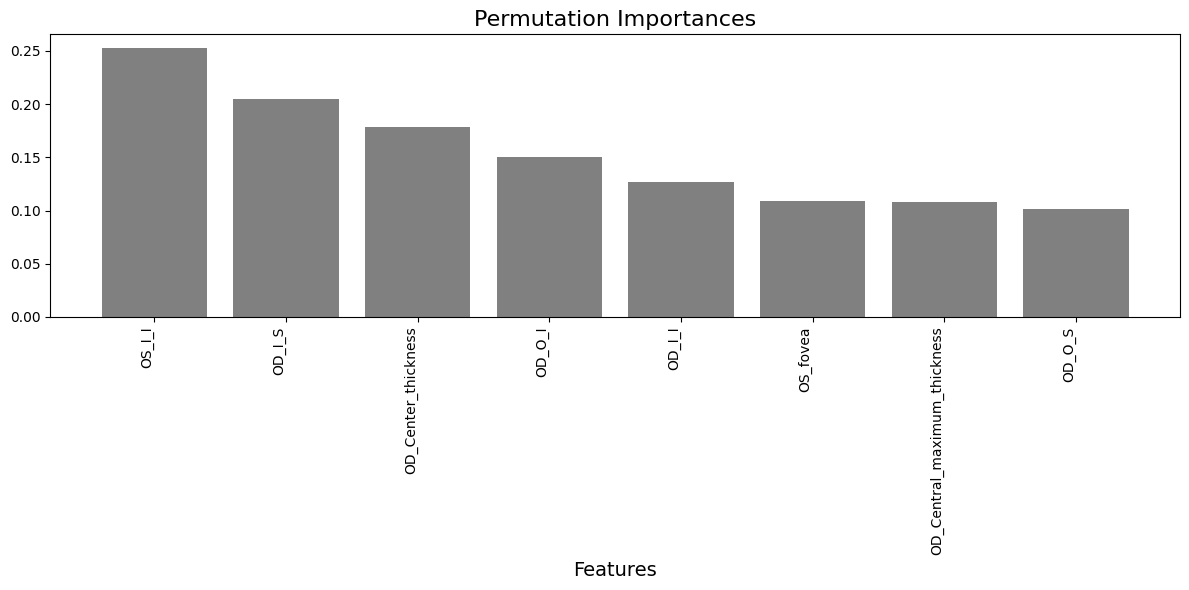

In [8]:
import matplotlib.pyplot as plt

# Top 8 features
top_n = 8
perm_top = perm_df.sort_values('Importance', ascending=False).head(top_n)

plt.figure(figsize=(12,6))

plt.bar(
    perm_top['Feature'],
    perm_top['Importance'],
    color='grey',
    edgecolor='none'
)

plt.xticks(rotation=90, ha='right', fontsize=10)
# plt.ylabel("Permutation Importance")
plt.xlabel("Features", fontsize=14)
plt.title("Permutation Importances", fontsize=16)
plt.tight_layout()
plt.show()


In [9]:
from lime.lime_tabular import LimeTabularExplainer
import numpy as np
import pandas as pd

explainer = LimeTabularExplainer(
    training_data=X_train_best,
    feature_names=feature_names,
    class_names=['Healthy', 'Schizophrenia'],
    mode='classification',
    random_state=42
)

lime_values = []

for i in range(len(X_test_best)):

    exp = explainer.explain_instance(
        X_test_best[i],
        best_model.predict_proba,
        num_features=len(feature_names)
    )

    # store absolute contribution
    sample_importance = dict()

    for feature, weight in exp.as_list():
        for f in feature_names:
            if f in feature:
                sample_importance[f] = abs(weight)
                break

    lime_values.append(sample_importance)

In [10]:
lime_importance = {}

for feature in feature_names:
    values = [
        sample.get(feature, 0)
        for sample in lime_values
    ]
    
    lime_importance[feature] = np.mean(values)


lime_df = pd.DataFrame({
    "Feature": list(lime_importance.keys()),
    "Importance": list(lime_importance.values())
})


lime_df = lime_df.sort_values(
    "Importance",
    ascending=False
)

# print(lime_df)

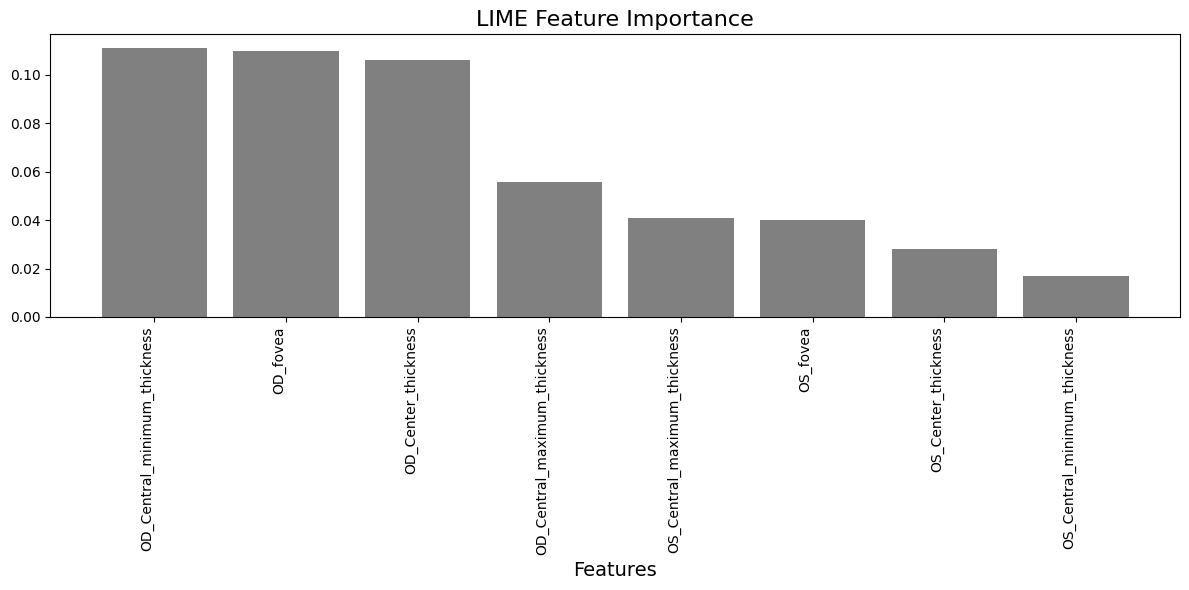

In [11]:
import matplotlib.pyplot as plt

top_n = 8

lime_top = lime_df.head(top_n)

plt.figure(figsize=(12,6))

plt.bar(
    lime_top['Feature'],
    lime_top['Importance'],
    color='grey',
    edgecolor='none'
)

plt.xticks(rotation=90, ha='right',fontsize=10)

plt.xlabel("Features", fontsize=14)
# plt.ylabel("Mean |LIME contribution|")

plt.title("LIME Feature Importance", fontsize=16)

plt.tight_layout()
plt.show()

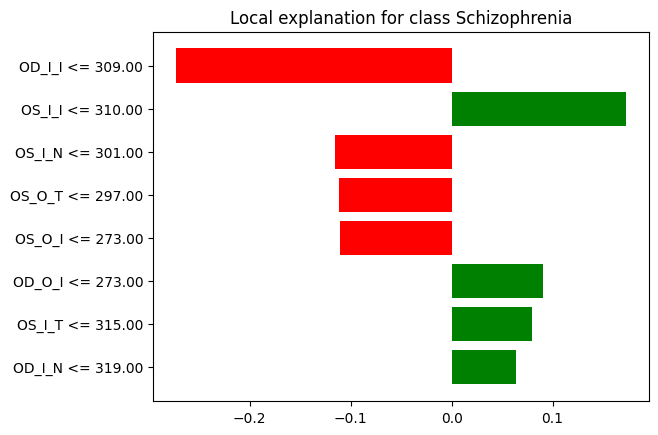

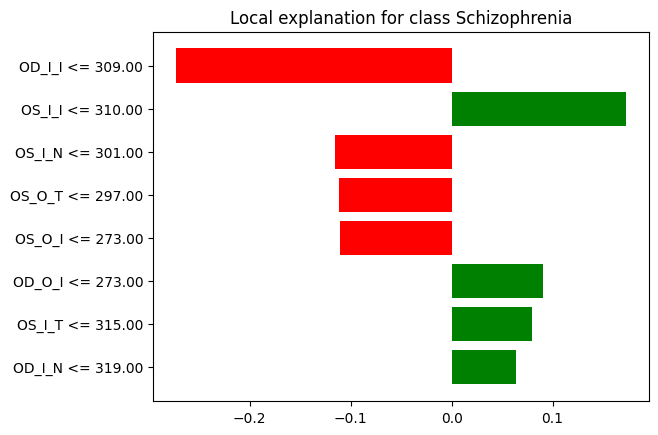

In [12]:
from lime.lime_tabular import LimeTabularExplainer

explainer = LimeTabularExplainer(
    training_data=X_train_best,
    feature_names=feature_names,
    class_names = ['Healthy', 'Schizophrenia'],
    mode='classification'
)

exp = explainer.explain_instance(
    X_test_best[0],
    best_model.predict_proba,
    num_features=8
)

exp.as_pyplot_figure()

In [23]:
# from PyALE import ale

# X_train_df = pd.DataFrame(
#     X_train_best,
#     columns=feature_names
# )

# # ale(
# #     X=X_train_df,
# #     model=best_model,
# #     feature=['RNFL']
# # )

In [35]:
# top_features = perm_top["Feature"].tolist()

# for feat in top_features:
#     print(f"ALE for: {feat}")

#     ale(
#     X=X_train_df,
#     model=best_model,
#     feature=[feat],
#     feature_type="continuous",
#     grid_size=20
# )

#     plt.show()

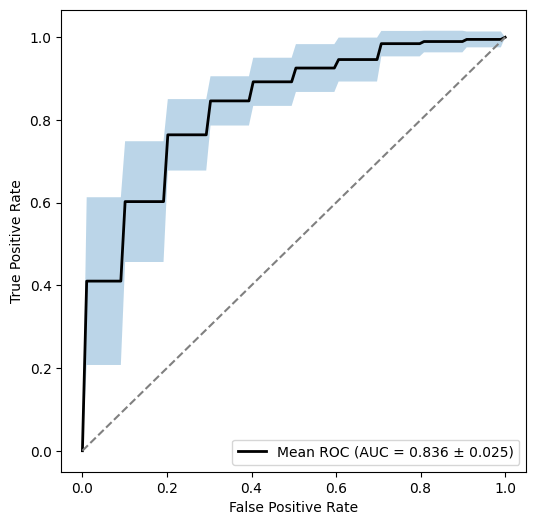

In [8]:

# # roc_results = {}
# # roc_data = {
# #     "mean_fpr": mean_fpr,
# #     "mean_tpr": mean_tpr,
# #     "std_tpr": std_tpr,
# #     "mean_auc": mean_auc,
# #     "std_auc": std_auc
# # }

# # np.save("./ROC_MLP.npy", roc_data)
plt.figure(figsize=(6, 6))

plt.plot(
    mean_fpr,
    mean_tpr,
    color='black',
    label=f'Mean ROC (AUC = {mean_auc:.3f} ± {std_auc:.3f})',
    lw=2
)

plt.fill_between(
    mean_fpr,
    mean_tpr - std_tpr,
    mean_tpr + std_tpr,
    alpha=0.3
)


plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
#plt.title('Mean ROC Curve with Standard Deviation')
plt.legend(loc='lower right')
#plt.grid(True)
plt.show()

(44,)


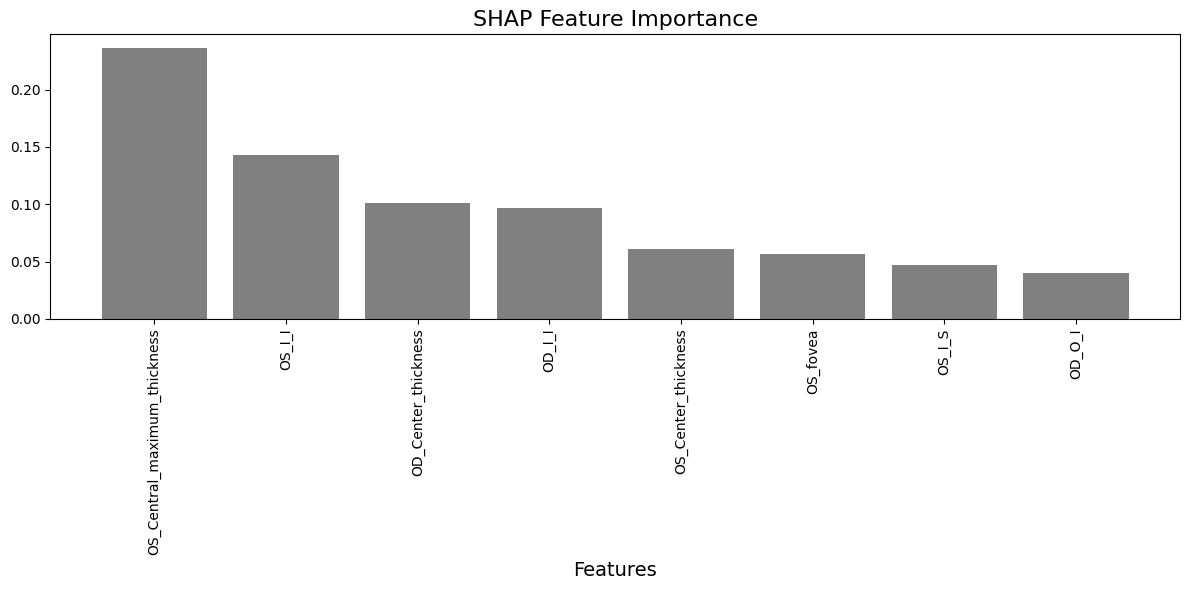

In [15]:
average_shap = []
for key in shap_values_dict:
    # tarr = np.array(shap_values_dict[key]['SV'][:,:,0].values)
    tarr = np.array(shap_values_dict[key]['SV'])
    average_shap.append(np.mean(np.abs(tarr),axis=0))
    
average_shap = np.array(average_shap)
finalmean = np.mean(average_shap, axis = 0)
print(np.shape(finalmean))

# Step 1: Combine arrays into a 2D array
combined_array = np.column_stack((feature_names, finalmean))

# Step 2: Sort by the second column (numbers) in descending order
sorted_array = combined_array[np.argsort(combined_array[:, 1].astype(float))[::-1]]

# Take top 5 most important features
top8 = sorted_array[:8]



# Plot
plt.figure(figsize=(12, 6), facecolor="none")
# plt.bar(col_keep[:-1], finalmean, color='red')
# plt.bar(sorted_array[:,0],np.round(np.array(sorted_array[:,1],dtype=np.float32), 4), color='gray')
plt.bar(top8[:, 0],np.round(top8[:, 1].astype(float), 4),color='gray')
plt.xlabel('Features', fontsize=14)
# plt.ylabel('Importance: mean(|SHAP|)', fontsize=14)
plt.title('SHAP Feature Importance', fontsize=16)
plt.xticks(rotation=90, fontsize=10)
plt.tight_layout()
# plt.savefig('./SHAPFeatureImp.png')
plt.show()

In [62]:
# # Compute ROC curve
# fpr, tpr, thresholds = roc_curve(y_test, y_pred_prob[:, 1])
# roc_auc = auc(fpr, tpr)

# # Plot
# plt.figure(figsize=(6, 6))
# plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.3f}')
# plt.plot([0, 1], [0, 1], linestyle='--')  # diagonal line
# plt.xlabel('False Positive Rate')
# plt.ylabel('True Positive Rate')
# plt.title('ROC Curve')
# plt.legend(loc='lower right')
# plt.grid(True)
# plt.show()

In [67]:
# # Making predictions
# y_pred = rf_classifier.predict(X_test)
# print(y_pred)


In [68]:
# summary = np.column_stack((y_test,y_pred))
# headers = ['y_test','y_pred']
# table = tabulate(summary, headers, tablefmt="fancy_grid")
# print(table)

In [69]:
# # Making predictions
# y_pred_prob = rf_classifier.predict_proba(X_test)
# print(y_pred_prob)

In [70]:
# summary = np.column_stack((y_test,y_pred_prob))
# headers = ['y_test','y_pred_0','y_pred_1','y_pred_2']
# table = tabulate(summary, headers, tablefmt="fancy_grid")
# print(table)

In [71]:
# print("Accuracy:", accuracy_score(y_test, y_pred))
# print("\nClassification Report:\n", classification_report(y_test, y_pred))
# print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

In [72]:
# Recompute class weights on best training data
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_best),
    y=y_train_best
)
class_weight_dict = {0: class_weights[0], 1: class_weights[1]}

# Train RF on best split
rf_best = RandomForestClassifier(
    class_weight=class_weight_dict,
    n_estimators=100,
    random_state=42
)

rf_best.fit(X_train_best, y_train_best)


RandomForestClassifier(class_weight={0: 1.1666666666666667, 1: 0.875},
                       random_state=42)

In [73]:
# Predict probabilities
y_test_prob = rf_best.predict_proba(X_test_best)[:, 1]

# Convert probabilities to class labels
y_test_pred = (y_test_prob >= 0.5).astype(int)

In [74]:
cm = confusion_matrix(y_test_best, y_test_pred)
print(cm)


[[ 9  1]
 [ 0 13]]


<Figure size 600x500 with 0 Axes>

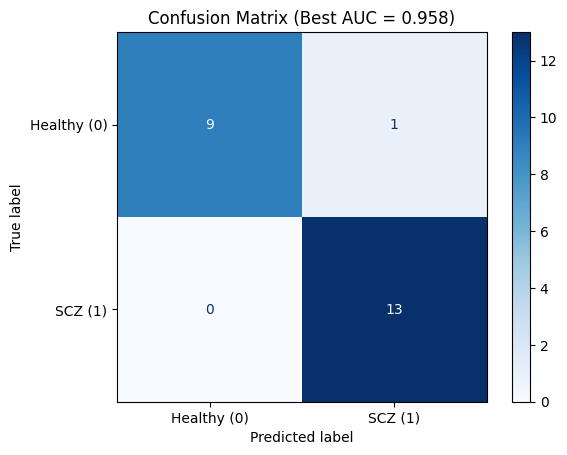

In [75]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Healthy (0)", "SCZ (1)"]
)

plt.figure(figsize=(6, 5))
disp.plot(cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix (Best AUC = {best_auc:.3f})")
plt.show()


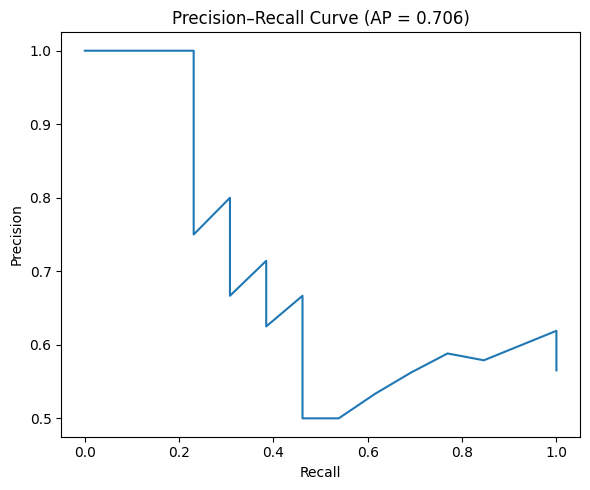

In [77]:
y_score = rf_classifier.predict_proba(X_test)[:, 1]

precision, recall, thresholds = precision_recall_curve(y_test, y_score)
ap = average_precision_score(y_test, y_score)

plt.figure(figsize=(6, 5))
plt.plot(recall, precision)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision–Recall Curve (AP = {ap:.3f})")
plt.tight_layout()
plt.show()

In [76]:
# # feature ranking
# # Get feature importances
# importances = rf_classifier.feature_importances_
# feature_names = ['OD_fovea', 'OD_I_S', 'OD_I_N', 'OD_I_I', 'OD_I_T', 'OD_O_S', 'OD_O_N', 'OD_O_I', 'OD_O_T', 'OD_Vol ', 'OD_I_S_Vol', 'OD_I_N_Vol', 
#                  'OD_I_I_Vol', 'OD_I_T_Vol', 'OD_O_S_Vol', 'OD_O_N_Vol', 'OD_O_I_Vol', 'OD_O_T_Vol', 'OD_Macula_volume', 'OD_Center_thickness', 
#                  'OD_Central_minimum_thickness', 'OD_Central_maximum_thickness', 'OS_fovea', 'OS_I_S', 'OS_I_N', 'OS_I_I', 'OS_I_T', 'OS_O_S', 'OS_O_N', 
#                  'OS_O_I', 'OS_O_T', 'OS_Vol ', 'OS_I_S_Vol', 'OS_I_N_Vol', 'OS_I_I_Vol', 'OS_I_T_Vol', 'OS_O_S_Vol', 'OS_O_N_Vol', 'OS_O_I_Vol', 'OS_O_T_Vol', 
#                  'OS_Macula_volume', 'OS_Center_thickness', 'OS_Central_minimum_thickness', 'OS_Central_maximum_thickness']

# # Rank features by importance
# feature_importances = pd.DataFrame({
#     'Feature': feature_names,
#     'Importance': importances
# }).sort_values(by='Importance', ascending=False)

# print(feature_importances)

# # Plot feature importances
# plt.figure(figsize=(10, 6))
# plt.bar(feature_importances['Feature'], feature_importances['Importance'], color='skyblue')
# plt.title('Feature Importances')
# plt.xlabel('Features')
# plt.ylabel('Importance')
# plt.xticks(rotation=90)
# plt.show()

In [77]:
# # SHAP for feature analysis
# shap.initjs()

In [78]:
# it is better to pass a Panda dataframe to SHAP
X_train_df = pd.DataFrame(X_train, columns=feature_names)

In [79]:
explainer = shap.TreeExplainer(rf_classifier)
shap_values = explainer(X_train_df)

print(np.shape(shap_values.values))

(49, 44, 2)


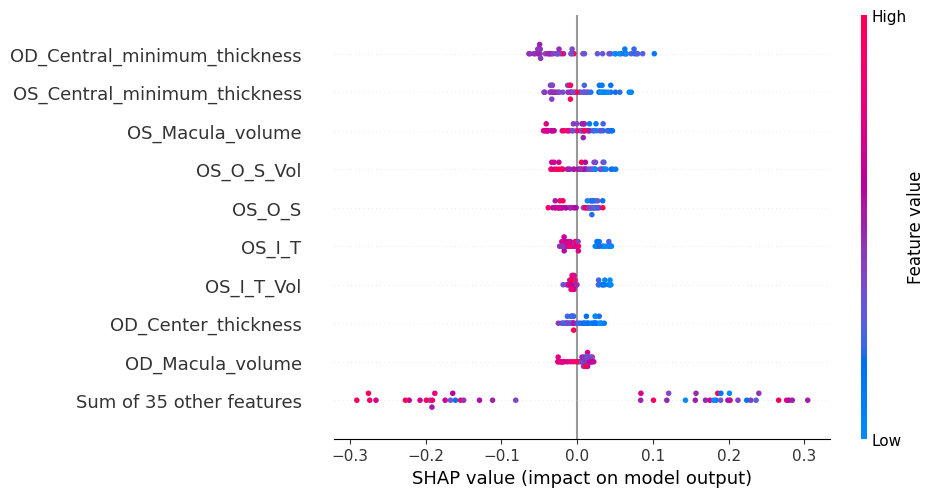

In [80]:
# Beeswarm plot
shap.plots.beeswarm(shap_values[:,:,1])

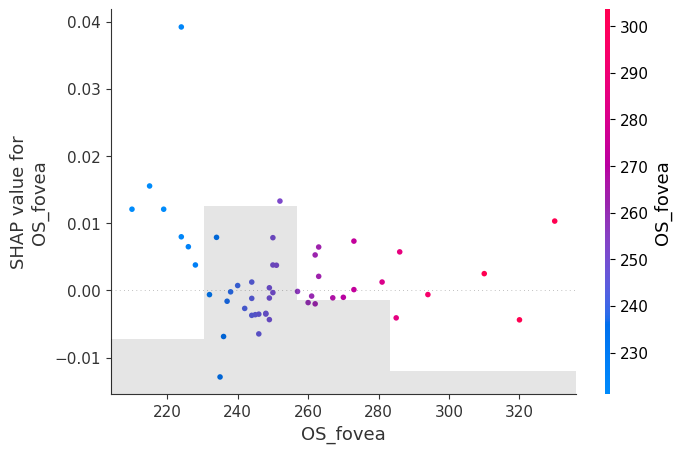

In [81]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_fovea',1], color=shap_values[:,'OS_fovea',1])

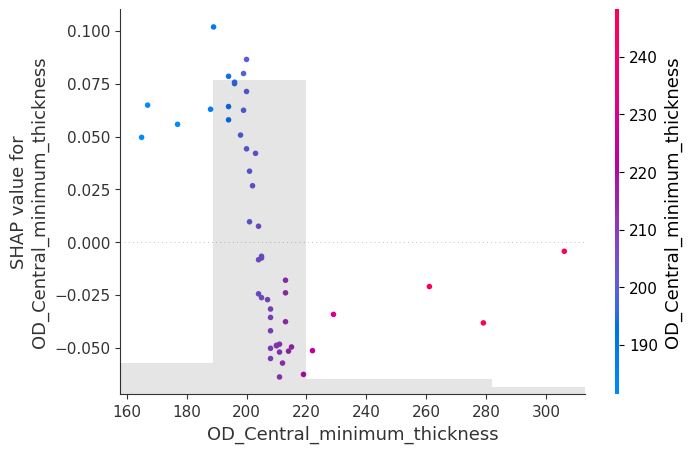

In [82]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OD_Central_minimum_thickness',1], color=shap_values[:,'OD_Central_minimum_thickness',1])

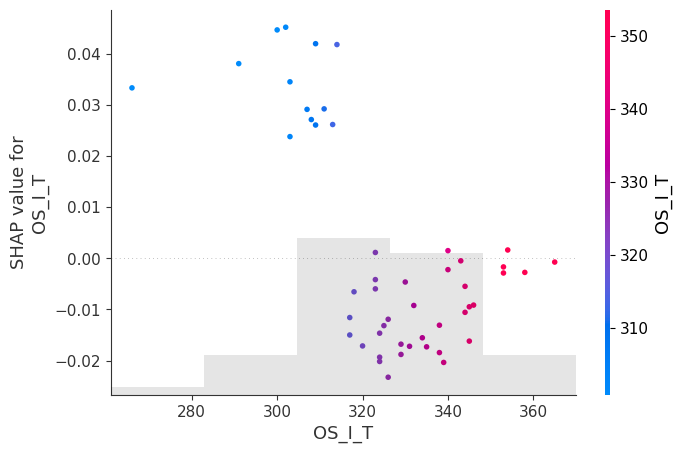

In [83]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_I_T',1], color=shap_values[:,'OS_I_T',1])

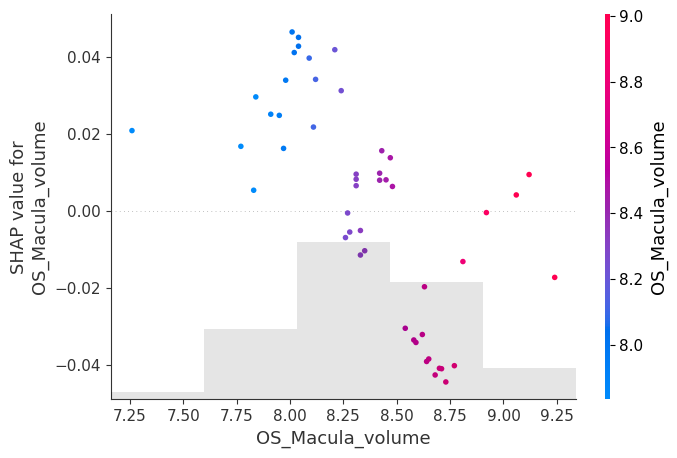

In [84]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_Macula_volume',1], color=shap_values[:,'OS_Macula_volume',1])

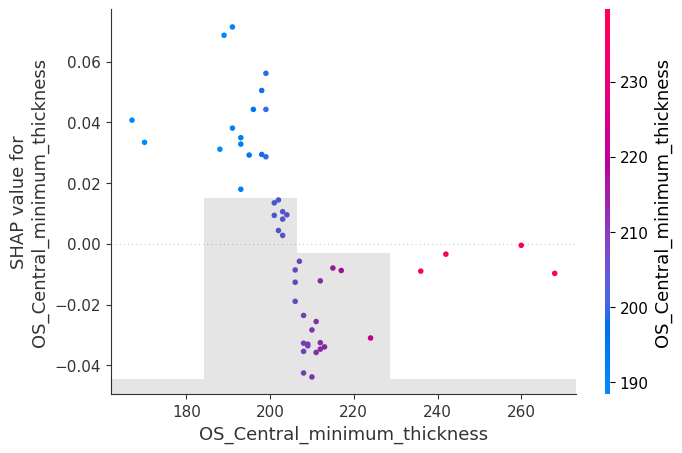

In [85]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OS_Central_minimum_thickness',1], color=shap_values[:,'OS_Central_minimum_thickness',1])

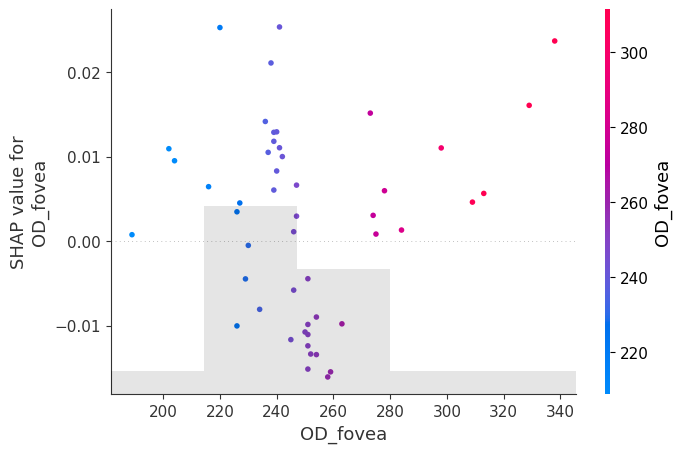

In [86]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OD_fovea',1], color=shap_values[:,'OD_fovea',1])

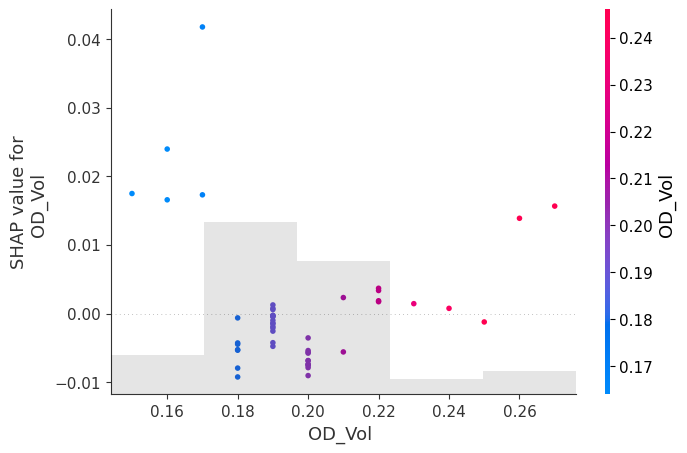

In [87]:
# Dependence plots
shap.plots.scatter(shap_values[:,'OD_Vol ',1], color=shap_values[:,'OD_Vol ',1])

In [88]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OS-T",0], color=shap_values[:,"OS-T",0])

In [89]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OS-I",0], color=shap_values[:,"OS-I",0])

In [90]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OS-N",0], color=shap_values[:,"OS-N",0])

In [91]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-S",0], color=shap_values[:,"OD-S",0])

In [92]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-T",0], color=shap_values[:,"OD-T",0])

In [93]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-I",0], color=shap_values[:,"OD-I",0])

In [94]:
# # Dependence plots
# shap.plots.scatter(shap_values[:,"OD-N",0], color=shap_values[:,"OD-N",0])